# Trabajo Fin de Máster Mantenimiento Predictivo

# Notebook 03 - Preprocesamiento de FD001

## Objetivo

Una vez completado el análisis exploratorio de FD001 y la comparación entre los cuatro subconjuntos de C-MAPSS, el siguiente paso consiste en preparar los datos para el desarrollo de los modelos de mantenimiento predictivo.

El preprocesamiento se realizará inicialmente sobre **FD001**, utilizado como escenario base por contener una única condición operativa y un único modo de degradación.

El objetivo de este notebook es analizar y definir las transformaciones necesarias para preparar los datos destinados a las dos tareas principales del proyecto:

- **Detección de anomalías y degradación.**
- **Estimación de la vida útil restante (RUL).**

Aunque ambas tareas parten de las mismas series temporales de sensores, algunos pasos del preprocesamiento podrán ser específicos para cada una de ellas.

Durante este notebook se estudiarán aspectos como la selección de variables, el tratamiento de variables constantes o de baja variabilidad, la definición de la RUL y la necesidad de aplicar transformaciones de escalado.

Finalmente, se generarán los conjuntos de datos procesados, conservando los valores originales de los sensores seleccionados. Las transformaciones que requieran ajustar parámetros a partir de los datos, como la estandarización, se realizarán posteriormente dentro de los procedimientos de entrenamiento y validación de cada modelo, evitando posibles fugas de información.

## 0. Importación de librerías necesarias en el notebook

Se importan las librerías necesarias para la carga, manipulación, análisis y visualización de los datos. Se utilizan las mismas herramientas empleadas en el análisis inicial de FD001.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import joblib

from sklearn.linear_model import LinearRegression

## 1. Carga de los datos

Para comenzar el preprocesamiento se cargarán los tres archivos correspondientes al subconjunto FD001:

- `train_FD001.txt`: contiene las trayectorias completas de los motores de entrenamiento hasta su final de vida.
- `test_FD001.txt`: contiene trayectorias truncadas de los motores utilizados para la evaluación.
- `RUL_FD001.txt`: contiene la RUL real correspondiente al último ciclo observado de cada motor del conjunto de test.

Los conjuntos de entrenamiento y prueba se mantendrán separados durante el proceso para evitar fugas de información (*data leakage*).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/TFM"
RAW_DATA_PATH = f"{PROJECT_PATH}/data/raw"
PROCESSED_DATA_PATH = f"{PROJECT_PATH}/data/processed"

In [ ]:
columns = (
    ["unit", "cycle"] +
    [f"op_setting_{i}" for i in range(1, 4)] +
    [f"sensor_{i}" for i in range(1, 22)]
)

In [ ]:
train = pd.read_csv(
    f"{RAW_DATA_PATH}/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

test = pd.read_csv(
    f"{RAW_DATA_PATH}/test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

rul_test = pd.read_csv(
    f"{RAW_DATA_PATH}/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

In [ ]:
print("TRAIN")
print("Dimensiones:", train.shape)
print("Motores:", train["unit"].nunique())

print("\nTEST")
print("Dimensiones:", test.shape)
print("Motores:", test["unit"].nunique())

print("\nRUL TEST")
print("Dimensiones:", rul_test.shape)

TRAIN
Dimensiones: (20631, 26)
Motores: 100

TEST
Dimensiones: (13096, 26)
Motores: 100

RUL TEST
Dimensiones: (100, 1)


El conjunto de entrenamiento contiene **20.631 observaciones correspondientes a 100 motores**, mientras que el conjunto de test contiene **13.096 observaciones de otros 100 motores**.

El archivo `RUL_FD001.txt` contiene **100 valores**, uno por cada motor del conjunto de test. Cada valor representa la vida útil restante del motor a partir del último ciclo disponible en su trayectoria de test.

Por tanto, los datos presentan una estructura coherente para continuar con el preprocesamiento: las trayectorias completas de entrenamiento permitirán construir la variable RUL durante el entrenamiento, mientras que las trayectorias truncadas de test y sus valores reales de RUL se utilizarán posteriormente para evaluar los modelos de prognosis.

## 2. Análisis de las variables

Antes de aplicar transformaciones a los datos, se analizará la variabilidad de las variables de entrada.

Las variables constantes no aportan capacidad discriminativa a los modelos, ya que mantienen el mismo valor para todas las observaciones. Por este motivo, se identificarán para valorar su eliminación durante el preprocesamiento.

También se revisarán las variables con un número muy reducido de valores diferentes, ya que una baja variabilidad no implica necesariamente que una variable deba eliminarse y deberá estudiarse de forma independiente.

### 2.1. Variables constantes

In [ ]:
unique_values = train.nunique()
print(unique_values)

unit             100
cycle            362
op_setting_1     158
op_setting_2      13
op_setting_3       1
sensor_1           1
sensor_2         310
sensor_3        3012
sensor_4        4051
sensor_5           1
sensor_6           2
sensor_7         513
sensor_8          53
sensor_9        6403
sensor_10          1
sensor_11        159
sensor_12        427
sensor_13         56
sensor_14       6078
sensor_15       1918
sensor_16          1
sensor_17         13
sensor_18          1
sensor_19          1
sensor_20        120
sensor_21       4745
dtype: int64


In [ ]:
# Identificación de variables constantes
constant_columns = [
    col for col in train.columns
    if train[col].nunique() == 1
]

print("Variables constantes:")
print(constant_columns)

Variables constantes:
['op_setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


Se han identificado las siguientes variables constantes en el conjunto de entrenamiento de FD001:

- `op_setting_3`
- `sensor_1`
- `sensor_5`
- `sensor_10`
- `sensor_16`
- `sensor_18`
- `sensor_19`

Estas variables presentan un único valor en todas las observaciones del conjunto de entrenamiento y, por tanto, una varianza nula.

Al no contener variación dentro de FD001, no proporcionan información útil para distinguir entre diferentes estados de funcionamiento o degradación de los motores. Por este motivo, se eliminarán de las variables utilizadas como entrada de los modelos desarrollados sobre FD001.

Esta decisión se aplica específicamente a este subconjunto y no implica que las mismas variables deban eliminarse automáticamente en FD002, FD003 o FD004.

### 2.2. Análisis de variables de baja variabilidad

Además de las variables constantes, se han identificado algunas variables con un número reducido de valores únicos. Sin embargo, una baja variabilidad no implica necesariamente que una variable carezca de información útil.

En particular, `sensor_6` presenta únicamente dos valores diferentes. Antes de decidir si debe conservarse o eliminarse, se analizará la frecuencia de ambos valores y su comportamiento a lo largo de las trayectorias de los motores.

In [ ]:
sensor_6_counts = train["sensor_6"].value_counts().sort_index()

print("Valores de sensor_6 y frecuencia:")
print(sensor_6_counts)

print("\nPorcentaje:")
print((train["sensor_6"].value_counts(normalize=True).sort_index() * 100).round(2))

Valores de sensor_6 y frecuencia:
sensor_6
21.60      406
21.61    20225
Name: count, dtype: int64

Porcentaje:
sensor_6
21.60     1.97
21.61    98.03
Name: proportion, dtype: float64


`sensor_6` presenta únicamente dos valores diferentes, `21.60` y `21.61`. Además, su distribución se encuentra fuertemente desbalanceada: el valor `21.61` representa aproximadamente el **98,03 %** de las observaciones, mientras que `21.60` aparece únicamente en el **1,97 %**.

Aunque este comportamiento indica una variabilidad muy reducida, no se eliminará la variable únicamente a partir de su número de valores únicos o de su frecuencia. Antes de tomar una decisión, se analizará si las apariciones del valor minoritario presentan alguna relación con el estado de degradación de los motores.

Para ello, se estudiará su distribución respecto a la **vida útil restante (RUL)**. Esto permitirá comprobar si el valor `21.60` se concentra, por ejemplo, en etapas próximas al final de vida o si aparece distribuido a lo largo de las trayectorias sin un patrón evidente.

#### 2.2.1. Relación de `sensor_6` con la RUL

Para estudiar si la reducida variabilidad de `sensor_6` contiene información relacionada con la degradación, se calculará temporalmente la RUL de cada observación del conjunto de entrenamiento.

En las trayectorias de entrenamiento de C-MAPSS, cada motor se encuentra monitorizado hasta su final de vida. Por tanto, la RUL de cada ciclo puede calcularse como la diferencia entre el último ciclo registrado para ese motor y el ciclo actual.

Una vez calculada, se analizará en qué momentos de la vida de los motores aparece el valor minoritario `21.60`. En particular, se comprobará:

- En cuántos motores aparece.
- Qué valores de RUL presentan las observaciones en las que `sensor_6 = 21.60`.
- Si estas apariciones se concentran cerca del final de vida o se distribuyen a lo largo de las trayectorias.

La RUL se utiliza en este punto únicamente como variable de análisis para estudiar el comportamiento del sensor, y no como variable de entrada de los futuros modelos de detección de anomalías.

In [ ]:
# Cálculo de la RUL para cada observación del conjunto de entrenamiento
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]

# Observaciones correspondientes al valor minoritario de sensor_6
sensor_6_low = train[train["sensor_6"] == 21.60]

print("Número de observaciones:", len(sensor_6_low))
print("Número de motores afectados:", sensor_6_low["unit"].nunique())

print("\nEstadísticos de RUL cuando sensor_6 = 21.60:")
print(sensor_6_low["RUL"].describe())

Número de observaciones: 406
Número de motores afectados: 62

Estadísticos de RUL cuando sensor_6 = 21.60:
count    406.000000
mean     170.204433
std       54.825065
min       43.000000
25%      131.000000
50%      171.000000
75%      205.000000
max      324.000000
Name: RUL, dtype: float64


In [ ]:
print("Porcentaje de apariciones según zona de RUL:")
print("RUL > 100:", round((sensor_6_low["RUL"] > 100).mean() * 100, 2), "%")
print("RUL 51-100:", round(sensor_6_low["RUL"].between(51, 100).mean() * 100, 2), "%")
print("RUL 0-50:", round(sensor_6_low["RUL"].between(0, 50).mean() * 100, 2), "%")

Porcentaje de apariciones según zona de RUL:
RUL > 100: 88.42 %
RUL 51-100: 11.08 %
RUL 0-50: 0.49 %


El valor minoritario `21.60` de `sensor_6` aparece en **406 observaciones correspondientes a 62 motores**, por lo que no se trata de un comportamiento exclusivo de un número reducido de unidades.

Sin embargo, su distribución respecto a la RUL muestra que estas apariciones no se concentran cerca del final de vida. El **88,42 %** de los casos se produce cuando quedan más de 100 ciclos de vida útil, mientras que únicamente el **0,49 %** aparece en los últimos 50 ciclos.

Además, cuando `sensor_6 = 21.60`, la RUL media es de aproximadamente **170 ciclos**, con valores comprendidos entre 43 y 324 ciclos. Por tanto, el cambio entre los dos valores de este sensor no parece constituir un indicador directo del acercamiento al final de vida.

Teniendo en cuenta que `sensor_6` presenta únicamente dos valores, que uno de ellos representa el **98,03 %** de las observaciones y que el valor minoritario no muestra una concentración asociada a valores bajos de RUL, se considera una variable de **muy baja variabilidad y escasa utilidad aparente para representar la degradación en FD001**.

Por este motivo, `sensor_6` se excluirá inicialmente de las variables predictoras utilizadas en los modelos de FD001.

### 2.3. Selección inicial de variables

A partir del análisis anterior se realizará una primera selección de las variables de entrada de FD001. Se eliminarán las variables constantes:

- `op_setting_3`
- `sensor_1`
- `sensor_5`
- `sensor_10`
- `sensor_16`
- `sensor_18`
- `sensor_19`

También se excluirá inicialmente `sensor_6`, debido a su reducida variabilidad y a que el análisis de su valor minoritario no muestra una relación evidente con la proximidad al final de vida.

Esta selección constituye una primera etapa del preprocesamiento. El resto de variables se conservarán por el momento, evitando eliminar sensores únicamente a partir de criterios como una correlación individual baja con la RUL, ya que podrían aportar información relevante en combinación con otras variables o para la detección de anomalías.

In [ ]:
# Variables que se excluirán inicialmente
columns_to_drop = [
    "op_setting_3",
    "sensor_1",
    "sensor_5",
    "sensor_6",
    "sensor_10",
    "sensor_16",
    "sensor_18",
    "sensor_19"
]

# Copias para el preprocesamiento
train_processed = train.drop(columns=columns_to_drop).copy()
test_processed = test.drop(columns=columns_to_drop).copy()

print("Dimensiones originales:")
print("Train:", train.shape)
print("Test:", test.shape)

print("\nDimensiones después de la selección inicial:")
print("Train:", train_processed.shape)
print("Test:", test_processed.shape)

print("\nVariables restantes:")
print(train_processed.columns.tolist())

Dimensiones originales:
Train: (20631, 27)
Test: (13096, 26)

Dimensiones después de la selección inicial:
Train: (20631, 19)
Test: (13096, 18)

Variables restantes:
['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'RUL']


Tras eliminar las variables constantes y `sensor_6`, el conjunto de entrenamiento pasa a contener **19 columnas**, incluyendo la variable objetivo `RUL`, mientras que el conjunto de test contiene **18 columnas**.

Las variables restantes incluyen los identificadores temporales (`unit` y `cycle`), dos variables asociadas a las condiciones operativas (`op_setting_1` y `op_setting_2`) y los sensores que presentan variabilidad suficiente para continuar su análisis.

En esta etapa todavía no se consideran todas estas columnas como variables predictoras. En particular, es necesario estudiar por separado el papel de `unit`, `cycle` y las variables operativas antes de definir definitivamente las entradas de los modelos.

## 3. Tratamiento de identificadores y variables operativas

Una vez realizada la selección inicial de variables, es necesario analizar por separado aquellas columnas que no corresponden directamente a mediciones de sensores.

En FD001 se distinguen:
- `unit`, que identifica el motor al que pertenece cada observación.
- `cycle`, que representa el ciclo temporal dentro de la trayectoria de cada motor.
- `op_setting_1` y `op_setting_2`, que contienen información relacionada con las condiciones de funcionamiento del sistema.

Estas variables tienen una naturaleza diferente a las señales proporcionadas por los sensores, por lo que se estudiará su función antes de decidir si deben utilizarse como entradas de los modelos.

En primer lugar, se analizará el papel de `unit` y `cycle`. Posteriormente, se estudiarán las variables operativas restantes de FD001.

### 3.1. Variables `unit` y `cycle`

Las variables `unit` y `cycle` cumplen funciones diferentes a las señales de sensores y, por tanto, no deben considerarse automáticamente como variables predictoras.

- `unit` identifica el motor al que pertenece cada observación. Su valor funciona como un identificador y no representa una característica física del sistema.
- `cycle` indica la posición temporal de cada observación dentro de la trayectoria del motor.

La variable `unit` será necesaria para agrupar las observaciones de cada motor, ordenar sus trayectorias y construir posteriormente secuencias temporales, pero no se utilizará como entrada de los modelos.

El tratamiento de `cycle` requiere un análisis adicional. Aunque contiene información temporal, utilizar directamente el número de ciclo como predictor podría hacer que el modelo aprendiera una relación entre la antigüedad del motor y su estado, en lugar de basar sus predicciones principalmente en la información proporcionada por los sensores.

Por este motivo, ambas variables se conservarán durante la preparación de los datos, pero se distinguirán de las variables predictoras utilizadas posteriormente por los modelos.

### 3.2. Análisis de las variables operativas

FD001 representa un escenario con una única condición operativa. Sin embargo, `op_setting_1` y `op_setting_2` presentan pequeñas variaciones numéricas dentro del conjunto de datos.

Antes de decidir si estas variables deben incluirse como entradas de los modelos, se analizará su distribución y magnitud de variación. Este análisis permitirá caracterizar las fluctuaciones de los parámetros operativos dentro de la única condición de funcionamiento definida para FD001 y fundamentar su tratamiento inicial.

In [ ]:
operating_settings = ["op_setting_1", "op_setting_2"]
train[operating_settings].describe().T

,count,mean,std,min,25%,50%,75%,max
op_setting_1,20631.0,-0.000009,0.002187,-0.0087,-0.0015,0.0,0.0015,0.0087
op_setting_2,20631.0,0.000002,0.000293,-0.0006,-0.0002,0.0,0.0003,0.0006


In [ ]:
for col in operating_settings:
    print(f"\n{col}")
    print("Media:", train[col].mean())
    print("Desviación estándar:", train[col].std())
    print("Mínimo:", train[col].min())
    print("Máximo:", train[col].max())
    print("Valores únicos:", train[col].nunique())


op_setting_1
Media: -8.87014686636615e-06
Desviación estándar: 0.0021873134490151044
Mínimo: -0.0087
Máximo: 0.0087
Valores únicos: 158

op_setting_2
Media: 2.3508312733265476e-06
Desviación estándar: 0.000293062124566125
Mínimo: -0.0006
Máximo: 0.0006
Valores únicos: 13


Aunque `op_setting_1` y `op_setting_2` presentan respectivamente 158 y 13 valores únicos, su rango de variación es muy reducido y ambas variables se encuentran centradas alrededor de cero.

`op_setting_1` presenta valores comprendidos entre -0,0087 y 0,0087, con una desviación estándar aproximada de 0,0022, mientras que `op_setting_2` varía entre -0,0006 y 0,0006, con una desviación estándar aproximada de 0,00029.

Estos resultados son coherentes con la definición de FD001 como un subconjunto correspondiente a una única condición operativa. Por tanto, las diferencias observadas en estas variables representan pequeñas variaciones dentro del mismo régimen de funcionamiento y no diferentes condiciones operativas como las observadas en FD002 y FD004.

Dado que el objetivo inicial sobre FD001 es modelar principalmente la información relacionada con el estado y la degradación de los motores, las variables `op_setting_1` y `op_setting_2` no se utilizarán inicialmente como variables predictoras. No obstante, se conservarán en los datos originales, ya que el tratamiento de las condiciones operativas deberá reconsiderarse posteriormente al extender la metodología a subconjuntos como FD002 y FD004.

### 3.3. Definición inicial de las variables predictoras

A partir de los análisis anteriores, se establece una primera separación entre las variables necesarias para estructurar las series temporales y aquellas que se utilizarán como información predictiva.
- `unit` se conservará como identificador del motor, pero no se utilizará como variable predictora.
- `cycle` se conservará para mantener el orden temporal de las observaciones y construir las trayectorias o secuencias necesarias para los modelos.
- `op_setting_1` y `op_setting_2` no se utilizarán inicialmente como variables predictoras en FD001 debido a la existencia de una única condición operativa y a su reducida variación.
- Los sensores seleccionados constituirán las variables predictoras principales.

Esta separación permite mantener la información necesaria para organizar las series temporales sin introducir como entradas del modelo variables que actúan principalmente como identificadores o referencias temporales.

In [ ]:
sensor_features = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

print("Número de sensores seleccionados:", len(sensor_features))

Número de sensores seleccionados: 14


Tras este análisis, se seleccionan inicialmente **14 sensores como variables predictoras** para los modelos desarrollados sobre FD001. Las variables unit y cycle se conservarán para mantener la estructura temporal de las trayectorias, mientras que las variables operativas `op_setting_1` y `op_setting_2` no se incluirán inicialmente como entradas del modelo.

Esta selección constituye el conjunto inicial de características sobre el que se aplicarán las siguientes etapas de preprocesamiento.

## 4. Preparación de la variable objetivo RUL

Una de las tareas principales del proyecto será la estimación de la vida útil restante (*Remaining Useful Life*, RUL) de los motores.

En el conjunto de entrenamiento de C-MAPSS, las trayectorias se encuentran disponibles hasta el final de vida de cada motor. Por este motivo, es posible calcular la RUL de cada observación como la diferencia entre el último ciclo registrado para el motor y el ciclo actual.

Hasta este punto se ha utilizado una definición lineal de la RUL, en la que su valor disminuye en una unidad por cada ciclo transcurrido hasta alcanzar 0 en el último ciclo observado.

Sin embargo, antes de utilizar esta variable como objetivo de los modelos de prognosis, se estudiará su definición, ya que durante las primeras etapas de funcionamiento los sensores pueden no contener información suficiente para distinguir con precisión entre valores elevados de RUL.

Por este motivo, se comparará la RUL lineal con una representación limitada o *piecewise*, utilizada para evitar exigir al modelo estimaciones excesivamente precisas durante las etapas iniciales de funcionamiento.

### 4.1. RUL lineal

La primera aproximación consiste en utilizar una RUL lineal. Para cada motor, se considera que la vida útil restante disminuye progresivamente desde el primer ciclo registrado hasta alcanzar el valor 0 en el último ciclo de su trayectoria.

Esta definición conserva toda la información temporal disponible y proporciona un valor diferente de RUL para cada ciclo. Sin embargo, supone que desde las primeras etapas de funcionamiento es posible distinguir mediante los sensores cuántos ciclos de vida le quedan exactamente al motor.

Esta hipótesis puede resultar demasiado restrictiva cuando el sistema se encuentra todavía en una fase saludable y las señales de los sensores presentan pocos indicios de degradación.

In [ ]:
train_processed.loc[
    train_processed["unit"] == 1,
    ["unit", "cycle", "RUL"]
].head(10)

,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


In [ ]:
train_processed.loc[
    train_processed["unit"] == 1,
    ["unit", "cycle", "RUL"]
].tail(10)

,unit,cycle,RUL
182,1,183,9
183,1,184,8
184,1,185,7
185,1,186,6
186,1,187,5
187,1,188,4
188,1,189,3
189,1,190,2
190,1,191,1
191,1,192,0


La inspección de la trayectoria del motor 1 confirma que la variable RUL se ha calculado correctamente.

El motor dispone de 192 ciclos registrados. En el primer ciclo presenta una RUL de 191 ciclos, que disminuye progresivamente en una unidad por cada nueva observación hasta alcanzar `RUL = 0` en el ciclo 192, correspondiente al último ciclo disponible de su trayectoria de entrenamiento.

Por tanto, la definición utilizada representa correctamente una disminución lineal de la vida útil restante a lo largo de la trayectoria de cada motor.

### 4.2. RUL limitada o *piecewise*

Una alternativa a la RUL lineal consiste en establecer un valor máximo de RUL durante la fase inicial de funcionamiento del motor.

Bajo este planteamiento, los ciclos correspondientes a etapas tempranas reciben un mismo valor máximo de RUL. Cuando la vida útil restante desciende por debajo de dicho límite, la RUL comienza a disminuir linealmente hasta alcanzar 0 al final de la trayectoria.

Esta representación parte de la idea de que, durante una etapa inicial de funcionamiento saludable, puede no existir suficiente información en los sensores para estimar de forma precisa diferencias muy elevadas de vida útil restante.

De este modo, el problema de prognosis se centra especialmente en la fase en la que comienzan a aparecer patrones de degradación observables.

### 4.3. Distribución de la RUL lineal en FD001

Antes de establecer una posible limitación de la RUL, se analizará la distribución de los valores obtenidos mediante la definición lineal.

Este análisis permitirá conocer el rango de RUL presente en FD001 y determinar qué proporción de las observaciones corresponde a etapas con valores elevados de vida útil restante.

La elección de una RUL limitada no se realizará únicamente a partir de esta distribución, pero este análisis servirá como punto de partida para comprender el efecto que tendría establecer diferentes valores máximos.

In [ ]:
train_processed["RUL"].describe()

,RUL
count,20631.000000
mean,107.807862
std,68.880990
min,0.000000
25%,51.000000
50%,103.000000
75%,155.000000
max,361.000000


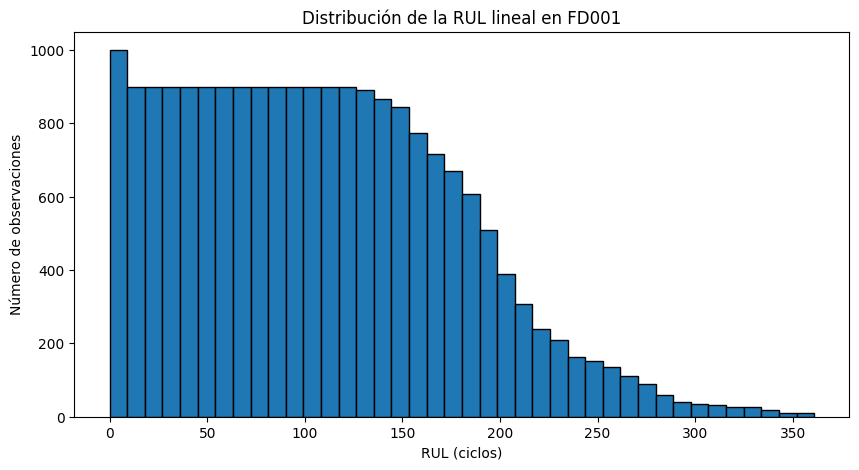

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    train_processed["RUL"],
    bins=40,
    edgecolor="black"
)

plt.xlabel("RUL (ciclos)")
plt.ylabel("Número de observaciones")
plt.title("Distribución de la RUL lineal en FD001")

plt.show()

La RUL lineal de FD001 presenta valores comprendidos entre **0 y 361 ciclos**, con una media aproximada de **107,81 ciclos** y una mediana de **103 ciclos**. El 50 % central de las observaciones se encuentra aproximadamente entre 51 y 155 ciclos de vida útil restante.

La distribución muestra una elevada presencia de observaciones con valores bajos y medios de RUL, mientras que el número de observaciones disminuye progresivamente para valores elevados. Este comportamiento está relacionado con las diferentes longitudes de las trayectorias de los motores: todos los motores aportan observaciones próximas al final de vida, mientras que únicamente aquellos con trayectorias más largas alcanzan valores elevados de RUL.

La existencia de valores de hasta 361 ciclos plantea además una cuestión relevante para el modelado. En las etapas iniciales de funcionamiento, cuando el motor todavía puede presentar un comportamiento esencialmente saludable, las señales disponibles podrían no contener información suficiente para diferenciar con precisión, por ejemplo, entre un motor con 300 ciclos restantes y otro con 200.

Por este motivo, además de la RUL lineal, se estudiará una representación limitada o *piecewise* que permita asignar un mismo valor máximo de RUL a las etapas iniciales de funcionamiento.

### 4.4. Análisis para la definición de una RUL limitada

La selección de un valor máximo para la RUL limitada constituye una decisión metodológica que debe justificarse y no establecerse únicamente de forma arbitraria.

Para ello, se analizará el comportamiento de los sensores de FD001 respecto a la RUL, con el objetivo de identificar a partir de los propios datos una región en la que las señales comienzan a desviarse de forma sistemática de su comportamiento inicial.

La selección del límite se realizará, por tanto, mediante un enfoque basado en los datos (*data-driven*), evitando establecer un valor máximo de RUL de forma arbitraria.

El límite seleccionado no debe interpretarse necesariamente como el instante físico exacto en el que comienza la degradación. Su función será representar una etapa inicial en la que no se exige al modelo diferenciar entre valores elevados de vida útil restante cuando las señales del sistema todavía presentan poca evidencia de degradación.

#### 4.4.1. Evolución media de sensores representativos respecto a la RUL

Para estudiar visualmente la transición entre las etapas iniciales de funcionamiento y las regiones de mayor degradación, se analizará la evolución de varios sensores que durante el análisis exploratorio mostraron una relación relevante con la RUL.

Debido al ruido presente en las mediciones individuales, las observaciones se agruparán por intervalos de RUL y se calculará el valor medio de cada sensor dentro de cada intervalo. Esta representación no se utilizará para transformar los datos de los futuros modelos, sino únicamente como herramienta exploratoria para facilitar la identificación de tendencias globales de degradación.

In [ ]:
# Crear intervalos de RUL de 10 ciclos para el análisis
train_analysis = train_processed.copy()

train_analysis["RUL_bin"] = (train_analysis["RUL"] // 10) * 10

sensors_analysis = [
    "sensor_4",
    "sensor_11",
    "sensor_12",
    "sensor_15"
]

sensor_rul_mean = (
    train_analysis
    .groupby("RUL_bin")[sensors_analysis]
    .mean()
    .reset_index()
)

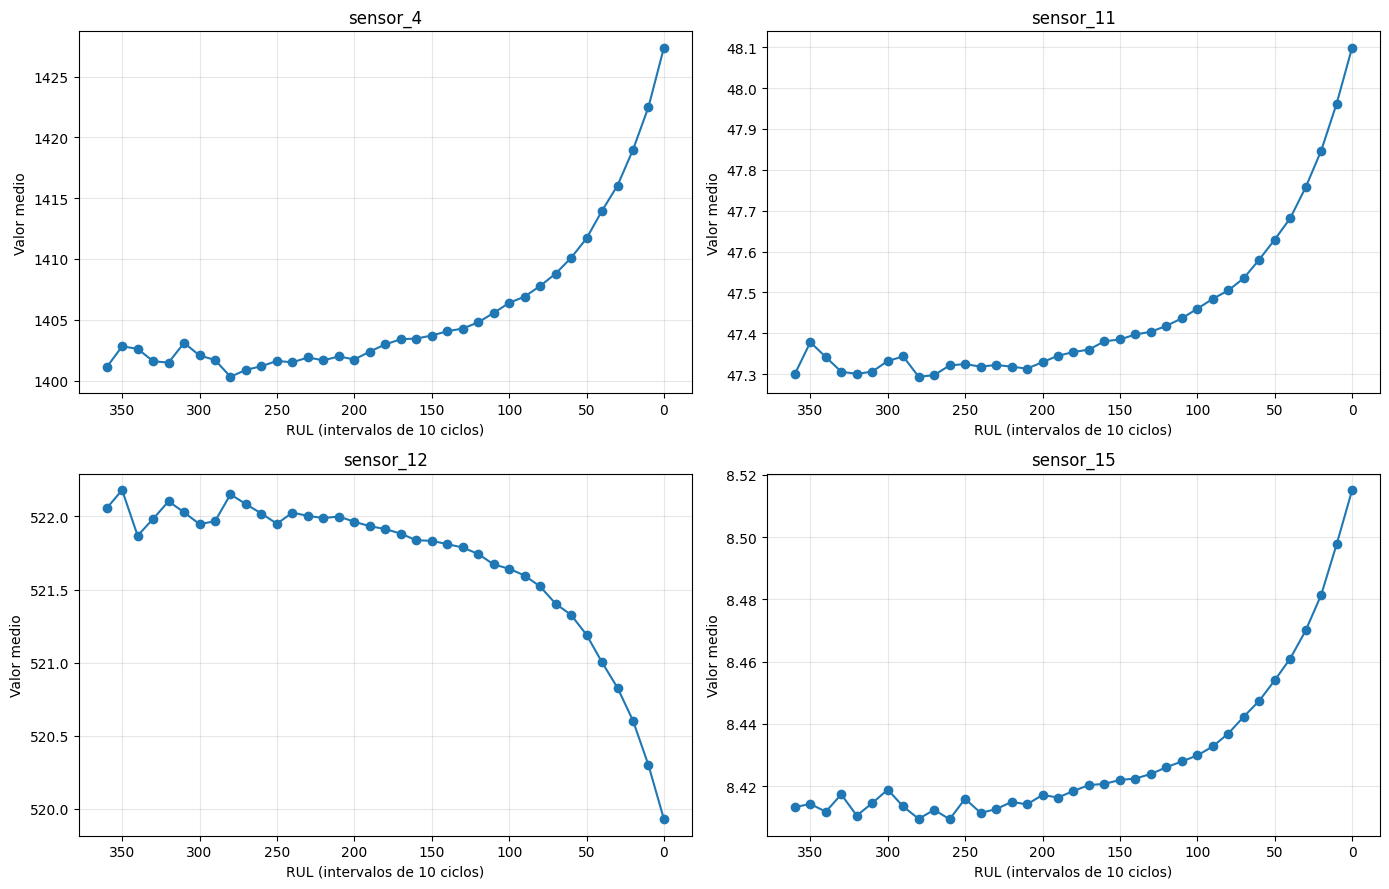

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes = axes.flatten()

for i, sensor in enumerate(sensors_analysis):

    axes[i].plot(
        sensor_rul_mean["RUL_bin"],
        sensor_rul_mean[sensor],
        marker="o"
    )

    axes[i].set_title(sensor)
    axes[i].set_xlabel("RUL (intervalos de 10 ciclos)")
    axes[i].set_ylabel("Valor medio")
    axes[i].grid(alpha=0.3)

    # RUL alta a la izquierda y final de vida a la derecha
    axes[i].invert_xaxis()

plt.tight_layout()

plt.show()

La representación de los valores medios por intervalos de RUL permite observar un patrón común en los sensores analizados.

Para valores elevados de RUL, correspondientes a las etapas iniciales de las trayectorias, los valores medios de los sensores permanecen relativamente estables y presentan únicamente pequeñas fluctuaciones. A medida que disminuye la vida útil restante comienzan a aparecer tendencias progresivas que se intensifican al aproximarse al final de vida.

En particular, `sensor_4`, `sensor_11` y `sensor_15` muestran una tendencia creciente conforme disminuye la RUL, mientras que `sensor_12` presenta una evolución decreciente. En todos los casos, los cambios son considerablemente más pronunciados en las etapas próximas al final de vida.

Visualmente, la transición no se produce en un único ciclo claramente definido, sino de forma progresiva. No obstante, aproximadamente entre **100 y 150 ciclos de RUL** las tendencias comienzan a hacerse más evidentes, mientras que para valores superiores los sensores presentan un comportamiento comparativamente más estable.

Este resultado respalda el uso de una RUL limitada o *piecewise*: durante las etapas iniciales, las señales presentan menor información observable sobre la degradación y puede no resultar adecuado exigir al modelo que diferencie con precisión entre valores elevados de RUL.

Sin embargo, este análisis visual no permite establecer por sí solo un valor máximo exacto de RUL. Por este motivo, será necesario complementar la inspección visual con un análisis cuantitativo que permita estudiar cómo se desvían conjuntamente los sensores respecto a las etapas iniciales de funcionamiento.

### 4.5. Estimación de la región de transición a partir de los datos

El análisis visual realizado anteriormente muestra que los sensores permanecen relativamente estables durante las etapas iniciales de funcionamiento y presentan cambios progresivamente más pronunciados conforme disminuye la RUL.

Sin embargo, seleccionar visualmente un valor máximo de RUL introduciría un componente subjetivo en el preprocesamiento. Por este motivo, se realizará un análisis cuantitativo orientado a identificar la región en la que las señales comienzan a desviarse de forma sistemática de su comportamiento inicial.

Para ello, se utilizarán varios sensores relacionados con la degradación y se analizará su desviación respecto a una región de referencia correspondiente a valores elevados de RUL.

El objetivo no será determinar un instante físico exacto de inicio de la degradación, ya que C-MAPSS no proporciona dicha etiqueta, sino identificar una región de transición respaldada por el comportamiento observado en los propios datos.

A partir de este análisis se establecerá posteriormente el valor máximo utilizado para construir la RUL limitada.

#### 4.5.1. Normalización de los sensores para el análisis de la transición

Los sensores seleccionados presentan escalas y unidades diferentes, por lo que sus variaciones no pueden compararse directamente. Para realizar un análisis conjunto de su evolución será necesario expresarlos previamente en una escala comparable.

Para ello, se estandarizarán únicamente con fines exploratorios los sensores utilizados en este análisis. La transformación permitirá expresar la evolución de cada señal en términos relativos y evitar que los sensores con valores numéricos más elevados tengan un peso mayor únicamente debido a su escala.

Esta normalización pertenece exclusivamente al análisis de la región de transición y no constituye todavía el escalado definitivo que se aplicará posteriormente a las variables de entrada de los modelos.

#### 4.5.2. Definición de una región inicial de referencia

Las trayectorias de FD001 presentan diferentes longitudes, por lo que utilizar un número fijo de ciclos iniciales podría representar proporciones distintas de la vida de cada motor.

Para disponer de una referencia comparable entre unidades, se calculará la posición relativa de cada observación dentro de la trayectoria de su motor. Esta variable tomará valores próximos a 0 al comienzo de la trayectoria y alcanzará 1 en el último ciclo registrado.

A partir de esta representación será posible seleccionar una pequeña fracción inicial de cada trayectoria como referencia del comportamiento temprano de los motores, sin utilizar la RUL para definir directamente dicha región.

In [ ]:
# Longitud total de la trayectoria de cada motor
train_analysis["max_cycle"] = (
    train_analysis.groupby("unit")["cycle"].transform("max")
)

# Posición relativa dentro de la trayectoria
train_analysis["relative_life"] = (
    (train_analysis["cycle"] - 1) /
    (train_analysis["max_cycle"] - 1)
)

train_analysis["relative_life"].describe()

,relative_life
count,20631.000000
mean,0.500000
std,0.290085
min,0.000000
25%,0.248718
50%,0.500000
75%,0.751282
max,1.000000


In [ ]:
train_analysis.loc[
    train_analysis["unit"].isin([1, 39, 69]),
    ["unit", "cycle", "max_cycle", "relative_life"]
].groupby("unit").agg(
    first_cycle=("cycle", "min"),
    last_cycle=("cycle", "max"),
    min_relative_life=("relative_life", "min"),
    max_relative_life=("relative_life", "max")
)

,first_cycle,last_cycle,min_relative_life,max_relative_life
unit,,,,
1,1,192,0.0,1.0
39,1,128,0.0,1.0
69,1,362,0.0,1.0


La variable `relative_life` se encuentra correctamente definida entre 0 y 1 para todas las trayectorias. Un valor de 0 representa el primer ciclo registrado de cada motor, mientras que un valor de 1 corresponde a su último ciclo.

La comprobación realizada sobre motores con diferentes longitudes de vida confirma que esta transformación permite expresar todas las trayectorias en una escala temporal común. Por ejemplo, los motores 1, 39 y 69 presentan 192, 128 y 362 ciclos respectivamente, pero todos quedan representados dentro del mismo intervalo relativo.

Esta variable no se utilizará como entrada de los modelos predictivos. Su finalidad en este análisis es únicamente facilitar la definición de una región inicial comparable entre motores que pueda utilizarse como referencia del comportamiento temprano.

#### 4.5.3. Análisis del comportamiento durante las etapas iniciales

Antes de establecer una región inicial de referencia, se analizará la evolución de los sensores seleccionados a lo largo de la vida relativa de los motores.

Para ello, las trayectorias se dividirán en intervalos correspondientes aproximadamente al 10 % de su duración. Posteriormente se calculará el valor medio de cada sensor dentro de cada intervalo.

Este análisis permitirá comprobar durante qué proporción inicial de las trayectorias las señales mantienen un comportamiento relativamente estable y evitará seleccionar directamente una región de referencia sin analizar previamente los datos.

In [ ]:
# Crear intervalos del 10 % de la vida relativa
train_analysis["life_bin"] = pd.cut(
    train_analysis["relative_life"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True
)

# Media de los sensores en cada intervalo
sensor_life_mean = (
    train_analysis
    .groupby("life_bin", observed=True)[sensors_analysis]
    .mean()
)

print(sensor_life_mean)

                  sensor_4  sensor_11   sensor_12  sensor_15
life_bin                                                    
(-0.001, 0.1]  1402.574392  47.346230  521.930446   8.417240
(0.1, 0.2]     1402.757632  47.357423  521.902718   8.418515
(0.2, 0.3]     1403.416134  47.372472  521.855076   8.421039
(0.3, 0.4]     1404.296191  47.401091  521.803039   8.423660
(0.4, 0.5]     1405.507936  47.433259  521.696220   8.427049
(0.5, 0.6]     1406.956565  47.482301  521.580667   8.433353
(0.6, 0.7]     1409.058807  47.547276  521.392567   8.442537
(0.7, 0.8]     1412.442394  47.646586  521.124094   8.456819
(0.8, 0.9]     1417.303685  47.793870  520.734236   8.474946
(0.9, 1.0]     1424.865088  48.026408  520.128333   8.505656


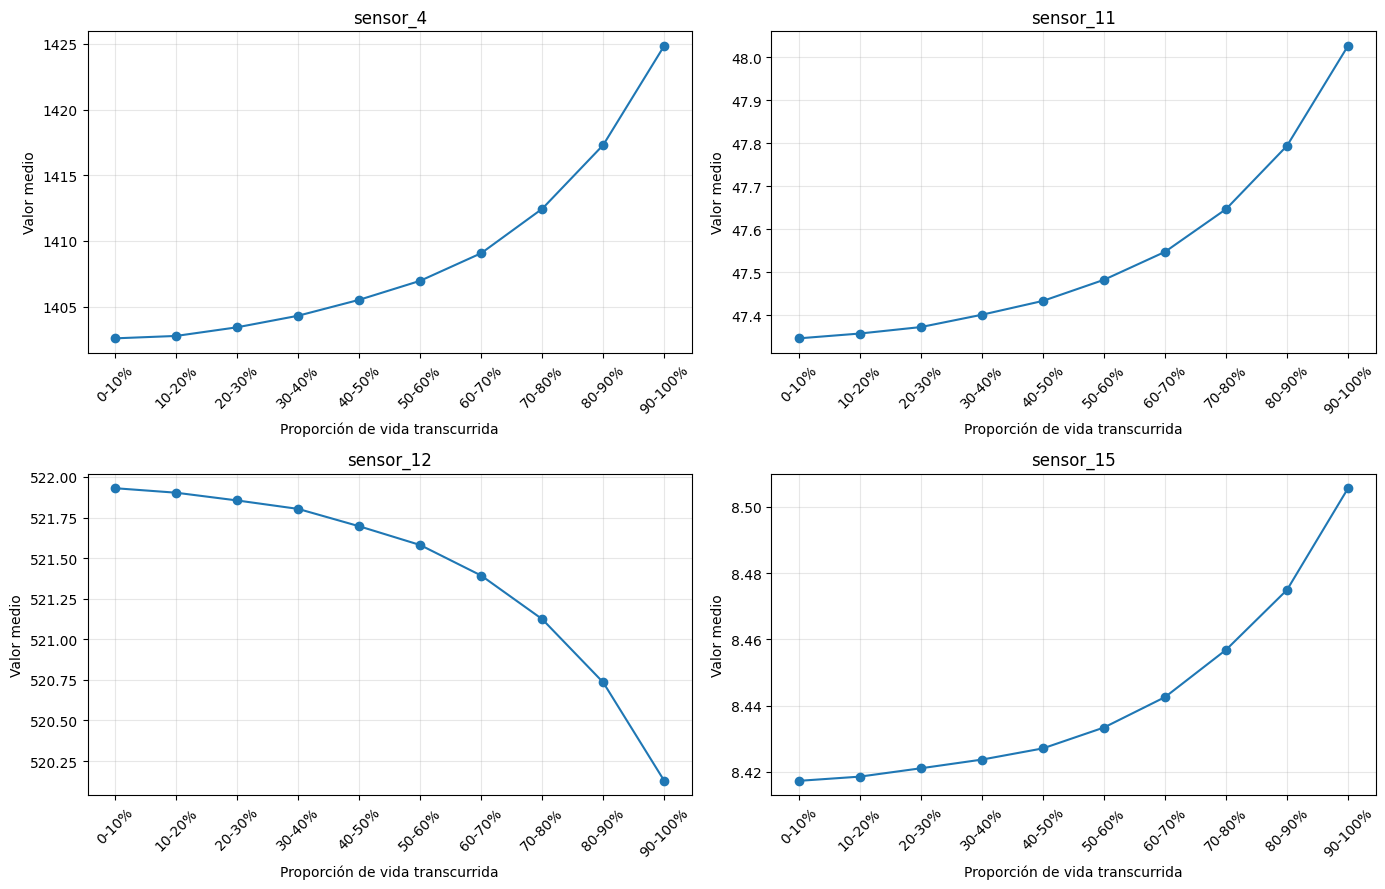

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

x = np.arange(len(sensor_life_mean))

for i, sensor in enumerate(sensors_analysis):
    axes[i].plot(
        x,
        sensor_life_mean[sensor],
        marker="o"
    )

    axes[i].set_title(sensor)
    axes[i].set_xlabel("Proporción de vida transcurrida")
    axes[i].set_ylabel("Valor medio")
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(
        [f"{j*10}-{(j+1)*10}%" for j in range(10)],
        rotation=45
    )
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

El análisis de los sensores respecto a la proporción de vida transcurrida muestra un comportamiento consistente entre las cuatro variables seleccionadas. Los sensores `sensor_4`, `sensor_11` y `sensor_15` presentan una evolución creciente, mientras que `sensor_12` muestra una tendencia decreciente.

Durante las primeras etapas de las trayectorias las variaciones son relativamente pequeñas. Sin embargo, los cambios se intensifican progresivamente conforme aumenta la proporción de vida transcurrida, siendo especialmente pronunciados durante las últimas etapas.

Por tanto, no se observa una separación brusca entre una fase completamente estable y una fase degradada. La evolución parece responder a un proceso gradual de degradación, lo que refuerza la idea de que no resulta adecuado determinar el inicio de la degradación únicamente mediante inspección visual.

Estos resultados permiten utilizar las primeras etapas de las trayectorias como referencia del comportamiento inicial, pero será necesario cuantificar posteriormente la magnitud de la desviación respecto a dicha referencia para identificar de forma más objetiva una posible región de transición.

#### 4.5.4. Definición de la referencia inicial

Para cuantificar la evolución de las señales se utilizará como referencia el primer 10 % de la trayectoria de cada motor.

Se selecciona el primer 10 % como una región inicial acotada que permite disponer de varias observaciones por motor sin extender excesivamente la referencia hacia etapas posteriores de la trayectoria. Esta elección se utiliza con fines exploratorios y no pretende identificar una fase estrictamente saludable ni un punto físico de inicio de la degradación.

Esta región no se interpretará como una etiqueta que garantice la ausencia total de degradación, sino como una muestra representativa del comportamiento observado al comienzo de las trayectorias. Su finalidad será proporcionar un nivel de referencia respecto al cual medir la evolución posterior de los sensores.

La utilización de una proporción relativa, en lugar de un número fijo de ciclos, permite además adaptar la región de referencia a las diferentes longitudes de vida presentes en FD001.

A partir de esta referencia se calculará, para cada sensor, cuánto se alejan progresivamente los diferentes intervalos de vida respecto a su comportamiento inicial.

In [ ]:
# Seleccionar el primer 10 % de cada trayectoria
reference_data = train_analysis[
    train_analysis["relative_life"] <= 0.10
]

# Media inicial de cada sensor para cada motor
reference_mean = (
    reference_data
    .groupby("unit")[sensors_analysis]
    .mean()
)

reference_mean.head()

,sensor_4,sensor_11,sensor_12,sensor_15
unit,,,,
1,1400.873000,47.268000,521.989000,8.412345
2,1396.894483,47.137241,522.413448,8.387769
3,1399.222222,47.230556,522.144444,8.410406
4,1403.340526,47.356316,521.865789,8.420621
5,1395.751852,47.152222,522.520741,8.400089


In [ ]:
# Número de observaciones utilizadas como referencia en cada motor
reference_counts = (
    reference_data
    .groupby("unit")
    .size()
)

reference_counts.describe()

,0
count,100.000000
mean,21.060000
std,4.690028
min,13.000000
25%,18.000000
50%,20.000000
75%,23.000000
max,37.000000


La utilización del primer 10 % de cada trayectoria proporciona una media de aproximadamente 21 observaciones por motor, con un mínimo de 13 y un máximo de 37 ciclos. Por tanto, la región seleccionada contiene varias observaciones para todas las unidades y permite caracterizar el comportamiento inicial sin depender de una única medición.

Además, las medias calculadas muestran que existen pequeñas diferencias entre los niveles iniciales de los distintos motores. Por este motivo, resulta conveniente establecer una referencia específica para cada unidad en lugar de utilizar una única referencia global para todo FD001.

De esta forma, la evolución posterior de cada sensor podrá analizarse respecto al comportamiento inicial del propio motor, reduciendo la influencia de las diferencias existentes entre unidades.

#### 4.5.5. Estandarización respecto al comportamiento inicial

Para comparar conjuntamente la evolución de sensores con diferentes escalas, se calculará la desviación estandarizada de cada medición respecto al comportamiento inicial del mismo motor.

Para cada motor y sensor se utilizarán la media y la desviación estándar obtenidas durante el primer 10 % de su trayectoria. Posteriormente, cada observación se transformará mediante:

$$
z_{i,s,t} = \frac{x_{i,s,t} - \mu_{i,s}^{ref}}{\sigma_{i,s}^{ref}}
$$

donde $x_{i,s,t}$ representa el valor del sensor, mientras que $\mu_{i,s}^{ref}$ y $\sigma_{i,s}^{ref}$ corresponden respectivamente a la media y desviación estándar del sensor durante la región inicial del mismo motor.

De esta forma, un valor próximo a 0 indica un comportamiento similar al observado inicialmente, mientras que valores con mayor magnitud representan una desviación progresivamente mayor respecto a dicha referencia.

Esta transformación se utilizará exclusivamente para analizar la evolución de la degradación y no corresponde todavía al escalado definitivo de las variables predictoras.

In [ ]:
reference_stats = (
    reference_data
    .groupby("unit")[sensors_analysis]
    .agg(["mean", "std"])
)

reference_stats.head()

sensor_4            sensor_11             sensor_12            \
             mean       std       mean       std        mean       std   
unit                                                                     
1     1400.873000  2.899822  47.268000  0.125220  521.989000  0.382910   
2     1396.894483  4.070939  47.137241  0.080485  522.413448  0.318863   
3     1399.222222  3.674106  47.230556  0.124214  522.144444  0.236847   
4     1403.340526  4.363172  47.356316  0.093584  521.865789  0.278873   
5     1395.751852  3.344991  47.152222  0.098813  522.520741  0.272000   

     sensor_15            
          mean       std  
unit                      
1     8.412345  0.021235  
2     8.387769  0.015564  
3     8.410406  0.019138  
4     8.420621  0.012337  
5     8.400089  0.019490

In [ ]:
train_deviation = train_analysis.copy()

for sensor in sensors_analysis:

    mean_by_unit = reference_stats[(sensor, "mean")]
    std_by_unit = reference_stats[(sensor, "std")]

    train_deviation[f"{sensor}_z"] = (
        train_deviation[sensor]
        - train_deviation["unit"].map(mean_by_unit)
    ) / train_deviation["unit"].map(std_by_unit)

In [ ]:
z_columns = [f"{sensor}_z" for sensor in sensors_analysis]

train_deviation[z_columns].describe()

,sensor_4_z,sensor_11_z,sensor_12_z,sensor_15_z
count,20631.000000,20631.000000,20631.000000,20631.000000
mean,1.676865,2.001805,-1.788047,1.278440
std,2.253622,2.572423,2.369210,1.848205
min,-4.318495,-3.564235,-13.476721,-4.305730
25%,0.122258,0.233319,-2.911431,0.001785
50%,1.187409,1.346597,-1.221036,0.966390
75%,2.761426,3.171192,-0.154647,2.229926
max,16.698612,15.513900,4.372246,15.013442


In [ ]:
train_deviation[z_columns].isna().sum()

,0
sensor_4_z,0
sensor_11_z,0
sensor_12_z,0
sensor_15_z,0


La estandarización respecto al comportamiento inicial se ha realizado correctamente para las 20.631 observaciones de FD001, sin generar valores ausentes en ninguno de los cuatro sensores analizados.

Los resultados muestran una evolución coherente con las tendencias identificadas anteriormente. A medida que avanzan las trayectorias, `sensor_4`, `sensor_11` y `sensor_15` tienden a desviarse en sentido positivo respecto a sus niveles iniciales, mientras que `sensor_12` tiende a hacerlo en sentido negativo. Este comportamiento coincide con las tendencias crecientes y decrecientes observadas durante el análisis exploratorio.

La existencia de valores estandarizados de elevada magnitud indica que, en determinadas etapas de las trayectorias, las mediciones llegan a encontrarse a varias desviaciones estándar de su comportamiento inicial. Esto resulta consistente con una separación progresiva respecto a la referencia conforme avanza el proceso de degradación.

A partir de estas variables estandarizadas será posible combinar la información de los distintos sensores en una medida común que represente la magnitud global de la desviación respecto al comportamiento inicial.

#### 4.5.6. Construcción de un índice conjunto de desviación

Una vez estandarizadas las señales respecto al comportamiento inicial de cada motor, se combinará la información de los sensores en un único índice de desviación.

Debido a que los sensores presentan diferentes direcciones de evolución, se utilizará el valor absoluto de las desviaciones estandarizadas. De esta forma, tanto un incremento como una disminución respecto al comportamiento inicial representarán un alejamiento de la referencia.

El índice conjunto se calculará como la media de las magnitudes de las desviaciones estandarizadas de los cuatro sensores analizados:

$$
D_t = \frac{|z_4| + |z_{11}| + |z_{12}| + |z_{15}|}{4}
$$

Valores reducidos del índice indicarán un comportamiento próximo al observado al comienzo de la trayectoria, mientras que valores progresivamente mayores representarán una mayor desviación conjunta de las señales respecto a dicha referencia.

Este índice se utilizará como herramienta exploratoria para estudiar cuándo comienza a intensificarse de forma sistemática la desviación de los sensores.

In [ ]:
train_deviation["deviation_index"] = (
    train_deviation[z_columns]
    .abs()
    .mean(axis=1)
)

train_deviation["deviation_index"].describe()

,deviation_index
count,20631.000000
mean,2.012182
std,1.775678
min,0.057746
25%,0.820059
50%,1.278159
75%,2.640514
max,11.493223


In [ ]:
train_deviation["RUL_bin"] = (
    train_deviation["RUL"] // 10
) * 10

deviation_by_rul = (
    train_deviation
    .groupby("RUL_bin")["deviation_index"]
    .mean()
    .reset_index()
)

deviation_by_rul

,RUL_bin,deviation_index
0,0,6.497853
1,10,5.287902
2,20,4.278165
3,30,3.524949
4,40,2.933434
5,50,2.418158
6,60,2.017794
7,70,1.718929
8,80,1.499760
9,90,1.325922


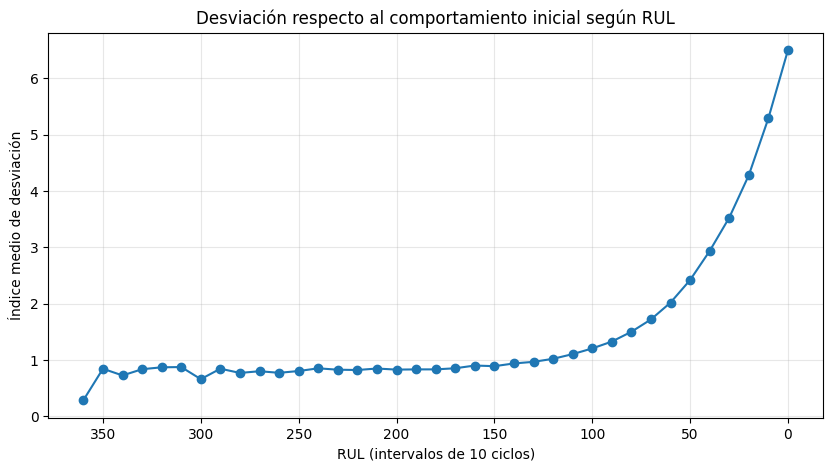

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    deviation_by_rul["RUL_bin"],
    deviation_by_rul["deviation_index"],
    marker="o"
)

plt.xlabel("RUL (intervalos de 10 ciclos)")
plt.ylabel("Índice medio de desviación")
plt.title("Desviación respecto al comportamiento inicial según RUL")

plt.grid(alpha=0.3)
plt.gca().invert_xaxis()

plt.show()

El índice conjunto muestra una evolución claramente relacionada con la vida útil restante del motor.

Para valores elevados de RUL, el índice permanece relativamente estable, con valores generalmente próximos a 0,8–0,9. Esto indica que, durante las primeras etapas de las trayectorias, las señales analizadas mantienen un comportamiento comparativamente próximo a la referencia inicial.

A medida que disminuye la RUL comienza a observarse un incremento progresivo del índice. Esta evolución se intensifica especialmente en las etapas próximas al final de vida, alcanzando valores considerablemente superiores a los observados durante las regiones iniciales.

Por tanto, el análisis conjunto de los sensores confirma cuantitativamente el patrón observado anteriormente de forma individual: la degradación no aparece como un cambio brusco en un único instante, sino como una desviación progresiva respecto al comportamiento inicial.

Visualmente puede identificarse una región intermedia en la que el índice comienza a abandonar su comportamiento aproximadamente estable. Sin embargo, seleccionar directamente un valor de RUL a partir de la gráfica seguiría introduciendo un componente subjetivo. Por este motivo, se analizará cuantitativamente el cambio en la evolución del índice antes de establecer el límite utilizado para la RUL limitada.

#### 4.5.7. Análisis del cambio del índice de desviación

La evolución del índice conjunto muestra una región relativamente estable para valores elevados de RUL y un crecimiento progresivo conforme se aproxima el final de vida.

Para identificar de forma más objetiva la transición entre ambas regiones, se analizará la variación del índice entre intervalos consecutivos de RUL.

El objetivo no será localizar el punto de máxima variación, ya que los cambios más intensos se producen naturalmente cerca del final de vida, sino estudiar a partir de qué región el índice comienza a presentar un crecimiento sostenido respecto al comportamiento observado para valores elevados de RUL.

In [ ]:
deviation_transition = (
    deviation_by_rul
    .sort_values("RUL_bin", ascending=False)
    .copy()
)

deviation_transition["increase"] = (
    deviation_transition["deviation_index"].diff()
)

deviation_transition

,RUL_bin,deviation_index,increase
36,360,0.285148,NaN
35,350,0.844014,0.558866
34,340,0.724915,-0.119099
33,330,0.835662,0.110747
32,320,0.869305,0.033643
31,310,0.874041,0.004737
30,300,0.659234,-0.214808
29,290,0.844558,0.185324
28,280,0.769491,-0.075067
27,270,0.799856,0.030365


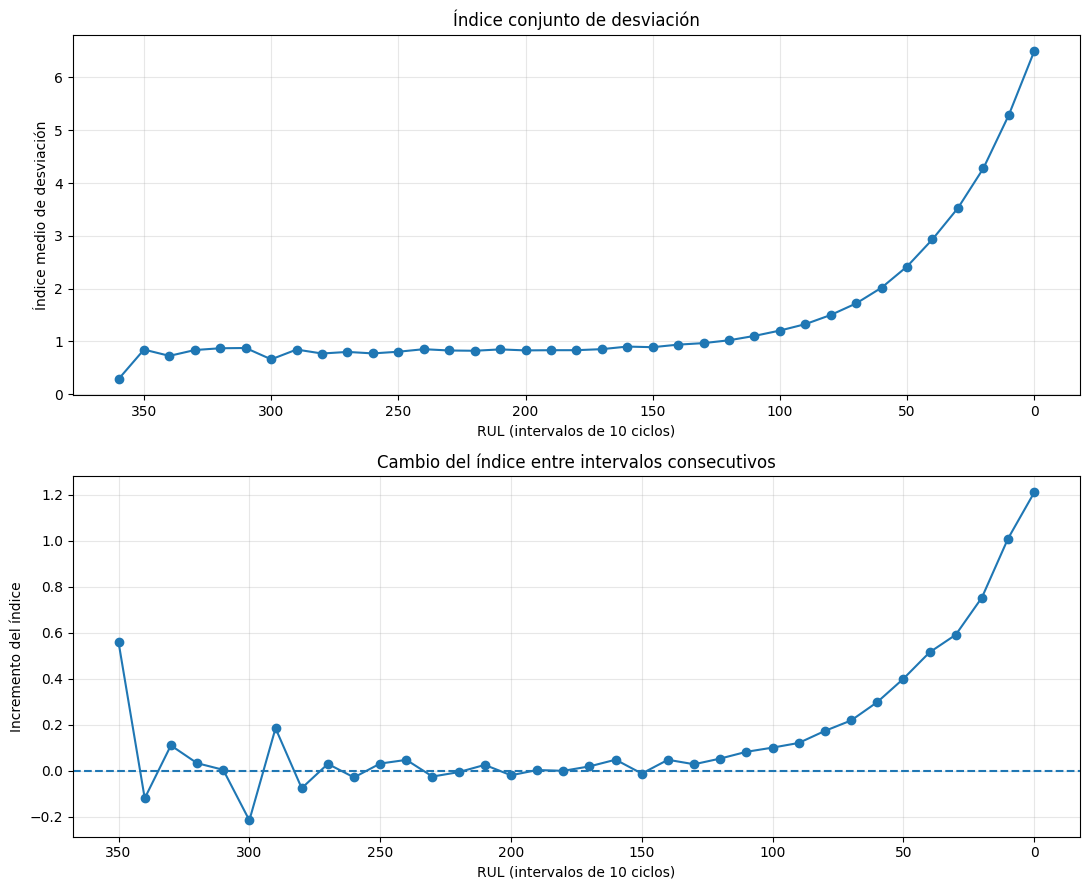

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(11, 9))

# Índice de desviación
axes[0].plot(
    deviation_transition["RUL_bin"],
    deviation_transition["deviation_index"],
    marker="o"
)

axes[0].set_title("Índice conjunto de desviación")
axes[0].set_xlabel("RUL (intervalos de 10 ciclos)")
axes[0].set_ylabel("Índice medio de desviación")
axes[0].invert_xaxis()
axes[0].grid(alpha=0.3)

# Cambio entre intervalos consecutivos
axes[1].plot(
    deviation_transition["RUL_bin"],
    deviation_transition["increase"],
    marker="o"
)

axes[1].axhline(0, linestyle="--")

axes[1].set_title("Cambio del índice entre intervalos consecutivos")
axes[1].set_xlabel("RUL (intervalos de 10 ciclos)")
axes[1].set_ylabel("Incremento del índice")
axes[1].invert_xaxis()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
deviation_transition.loc[
    deviation_transition["RUL_bin"].between(50, 200),
    ["RUL_bin", "deviation_index", "increase"]
]

,RUL_bin,deviation_index,increase
20,200,0.828585,-0.019046
19,190,0.832394,0.003809
18,180,0.832687,0.000293
17,170,0.852257,0.019570
16,160,0.900967,0.048710
15,150,0.889459,-0.011508
14,140,0.937754,0.048294
13,130,0.966611,0.028858
12,120,1.020266,0.053654
11,110,1.103283,0.083018


El análisis de las diferencias entre intervalos consecutivos permite distinguir con mayor claridad las distintas etapas de evolución del índice.

Para valores elevados de RUL, las variaciones entre intervalos son reducidas y oscilan alrededor de cero, lo que indica que el índice de desviación permanece aproximadamente estable. Estas oscilaciones son especialmente visibles en los valores de RUL más elevados, donde además existe un menor número de motores con trayectorias suficientemente largas.

A medida que disminuye la RUL, las variaciones comienzan a ser predominantemente positivas. En las regiones próximas al final de vida, los incrementos aumentan progresivamente, mostrando una aceleración clara de la desviación respecto al comportamiento inicial.

Los resultados sugieren, por tanto, la existencia de una transición entre una región de relativa estabilidad y otra de crecimiento progresivo de la desviación. No obstante, todavía resulta necesario establecer un criterio cuantitativo que permita localizar dicha transición sin seleccionar el límite únicamente mediante inspección visual.

#### 4.5.8. Estimación del punto de transición mediante regresión segmentada

Para reducir la subjetividad en la selección de la región de transición, se realizará una estimación cuantitativa mediante un procedimiento de regresión segmentada.

El objetivo consiste en aproximar la evolución del índice conjunto de desviación mediante dos regiones: una primera asociada a un comportamiento comparativamente estable y una segunda caracterizada por un incremento progresivo de la desviación conforme se aproxima el final de vida.

Se evaluarán diferentes valores de RUL como posibles puntos de separación. Para cada candidato se ajustará una regresión lineal a cada una de las dos regiones y se calculará el error cuadrático total de ambos ajustes.

El punto que minimice este error se considerará una estimación del cambio de régimen en la evolución del índice. Este procedimiento no pretende identificar el instante físico exacto en el que comienza la degradación, sino obtener un criterio reproducible basado en el comportamiento observado en los datos.

In [ ]:
# Región utilizada para estimar el cambio de régimen
transition_data = (
    deviation_by_rul[
        deviation_by_rul["RUL_bin"] <= 200
    ]
    .sort_values("RUL_bin")
    .reset_index(drop=True)
)

candidate_results = []

# Evitar puntos demasiado próximos a los extremos
for breakpoint in transition_data["RUL_bin"][3:-3]:

    region_low = transition_data[
        transition_data["RUL_bin"] <= breakpoint
    ]

    region_high = transition_data[
        transition_data["RUL_bin"] > breakpoint
    ]

    model_low = LinearRegression()
    model_high = LinearRegression()

    model_low.fit(
        region_low[["RUL_bin"]],
        region_low["deviation_index"]
    )

    model_high.fit(
        region_high[["RUL_bin"]],
        region_high["deviation_index"]
    )

    pred_low = model_low.predict(region_low[["RUL_bin"]])
    pred_high = model_high.predict(region_high[["RUL_bin"]])

    sse_low = np.sum(
        (region_low["deviation_index"] - pred_low) ** 2
    )

    sse_high = np.sum(
        (region_high["deviation_index"] - pred_high) ** 2
    )

    candidate_results.append({
        "breakpoint": breakpoint,
        "total_sse": sse_low + sse_high
    })

breakpoint_results = pd.DataFrame(candidate_results)

breakpoint_results.sort_values("total_sse").head(10)

,breakpoint,total_sse
2,50,0.697054
3,60,0.754515
1,40,0.924916
4,70,1.033584
5,80,1.505174
0,30,1.563011
6,90,2.137960
7,100,2.927476
8,110,3.837959
9,120,4.843513


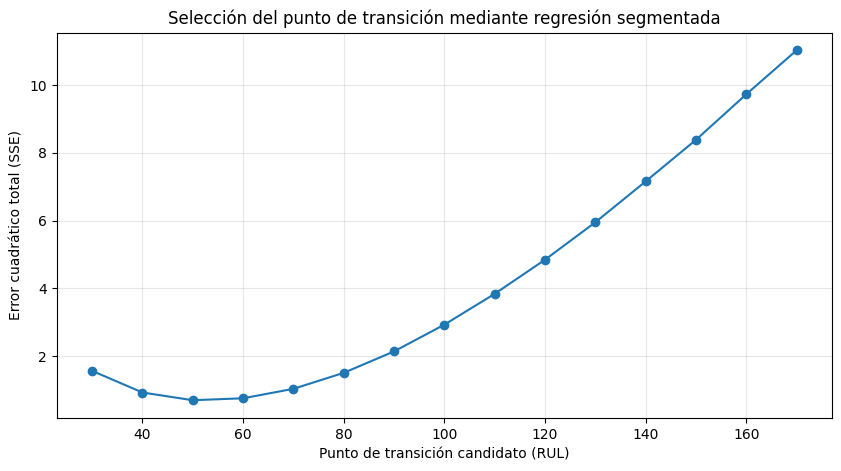

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    breakpoint_results["breakpoint"],
    breakpoint_results["total_sse"],
    marker="o"
)

plt.xlabel("Punto de transición candidato (RUL)")
plt.ylabel("Error cuadrático total (SSE)")
plt.title("Selección del punto de transición mediante regresión segmentada")

plt.grid(alpha=0.3)
plt.show()

La regresión segmentada presenta su menor error para un punto de separación situado alrededor de 50 ciclos de RUL. Sin embargo, este resultado debe interpretarse teniendo en cuenta la forma de la evolución del índice de desviación.

El índice no presenta dos regiones claramente lineales, sino una evolución aproximadamente estable durante las etapas iniciales seguida de un crecimiento progresivo y acelerado conforme se aproxima el final de vida. Como consecuencia, el ajuste mediante dos regresiones lineales tiende a situar el punto de separación en una región relativamente próxima al final de vida, donde el crecimiento del índice se hace más pronunciado.

Por tanto, el mínimo error obtenido mediante este procedimiento identifica principalmente un cambio en la intensidad del crecimiento, pero no necesariamente el comienzo de la desviación respecto al comportamiento inicial.

Dado que el objetivo del análisis es estimar la transición desde una región relativamente estable hacia una desviación sostenida, este criterio no se utilizará de forma aislada para establecer el valor máximo de RUL. Será necesario analizar directamente cuándo el índice comienza a separarse de la variabilidad característica de la región inicial.

#### 4.5.9. Definición de un umbral a partir de la variabilidad inicial

Como alternativa al ajuste mediante regresión segmentada, se analizará directamente la variabilidad que presenta el índice conjunto durante la región utilizada como referencia inicial.

La existencia de ruido y variabilidad natural en las mediciones implica que pequeñas desviaciones respecto a la media inicial no deben interpretarse necesariamente como evidencia de degradación. Por este motivo, se caracterizará la distribución del índice de desviación durante el primer 10 % de las trayectorias.

Esta distribución permitirá establecer un nivel de referencia que represente la variabilidad observada durante las etapas iniciales. Posteriormente se estudiará a partir de qué valores de RUL el índice conjunto supera dicho nivel de forma sostenida.

Este enfoque permite definir la transición en relación con el comportamiento inicial observado en los propios datos, en lugar de establecer directamente un valor de RUL predeterminado.

In [ ]:
initial_deviation = train_deviation.loc[
    train_deviation["relative_life"] <= 0.10,
    "deviation_index"
]

initial_deviation.describe()

,deviation_index
count,2106.000000
mean,0.784562
std,0.284855
min,0.093141
25%,0.578473
50%,0.764405
75%,0.969446
max,2.047303


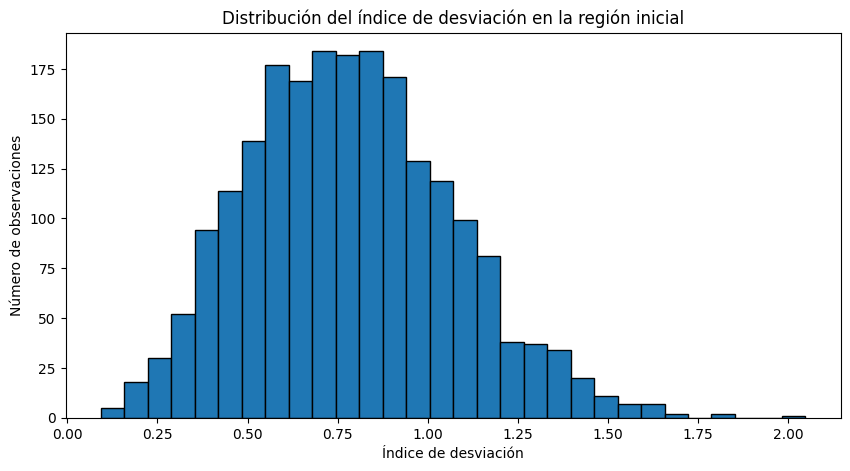

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    initial_deviation,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Índice de desviación")
plt.ylabel("Número de observaciones")
plt.title("Distribución del índice de desviación en la región inicial")

plt.show()

In [ ]:
initial_mean = initial_deviation.mean()
initial_std = initial_deviation.std()

print(f"Media inicial: {initial_mean:.4f}")
print(f"Desviación estándar inicial: {initial_std:.4f}")

print(f"Media + 1σ: {initial_mean + initial_std:.4f}")
print(f"Media + 2σ: {initial_mean + 2 * initial_std:.4f}")
print(f"Media + 3σ: {initial_mean + 3 * initial_std:.4f}")

Media inicial: 0.7846
Desviación estándar inicial: 0.2849
Media + 1σ: 1.0694
Media + 2σ: 1.3543
Media + 3σ: 1.6391


El índice de desviación durante la región inicial presenta una media de 0,785 y una mediana de 0,764. La mayor parte de las observaciones se concentra aproximadamente entre 0,58 y 0,97, aunque la distribución presenta cierta asimetría hacia valores elevados y alcanza un máximo de 2,05.

Esta distribución confirma que incluso durante las primeras etapas existen variaciones naturales respecto al comportamiento medio inicial. Por tanto, una observación con un índice de desviación distinto de cero no debe interpretarse directamente como evidencia de degradación.

Debido a que la distribución no es perfectamente simétrica, se utilizará un criterio basado en percentiles empíricos en lugar de asumir una distribución normal y establecer el umbral únicamente mediante múltiplos de la desviación estándar.

De esta forma, el umbral podrá definirse directamente a partir de la variabilidad observada en los datos de referencia.

#### 4.5.10. Análisis de percentiles de la región inicial

Para establecer un límite basado en la variabilidad observada durante las etapas iniciales, se calcularán diferentes percentiles de la distribución del índice de desviación.

Los percentiles representan directamente la proporción de observaciones iniciales situadas por debajo de un determinado valor y no requieren asumir una distribución estadística concreta.

Se analizarán los percentiles 90, 95 y 99 con el objetivo de estudiar cómo cambia la detección de la transición en función del nivel de exigencia utilizado. La selección final no se realizará únicamente a partir del valor del percentil, sino también considerando si la superación del umbral se mantiene de forma sostenida conforme disminuye la RUL.

In [ ]:
percentiles = initial_deviation.quantile([0.90, 0.95, 0.99])
print(percentiles)

0.90    1.161911
0.95    1.286210
0.99    1.490860
Name: deviation_index, dtype: float64


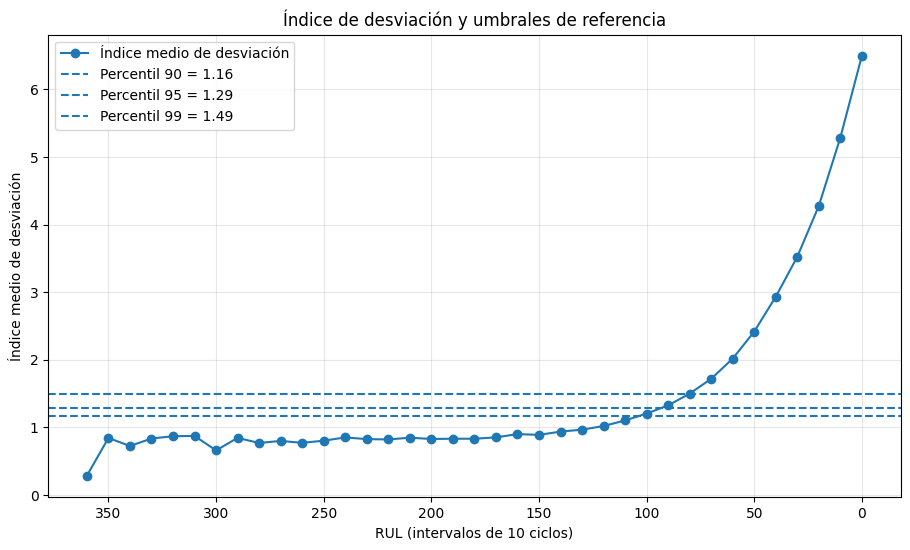

In [ ]:
plt.figure(figsize=(11, 6))

plt.plot(
    deviation_by_rul["RUL_bin"],
    deviation_by_rul["deviation_index"],
    marker="o",
    label="Índice medio de desviación"
)

for percentile, threshold in percentiles.items():
    plt.axhline(
        threshold,
        linestyle="--",
        label=f"Percentil {int(percentile * 100)} = {threshold:.2f}"
    )

plt.xlabel("RUL (intervalos de 10 ciclos)")
plt.ylabel("Índice medio de desviación")
plt.title("Índice de desviación y umbrales de referencia")

plt.gca().invert_xaxis()
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [ ]:
threshold_analysis = deviation_by_rul.copy()

for percentile, threshold in percentiles.items():
    threshold_analysis[
        f"above_p{int(percentile * 100)}"
    ] = threshold_analysis["deviation_index"] > threshold

threshold_analysis.loc[
    threshold_analysis["RUL_bin"].between(50, 180)
]

,RUL_bin,deviation_index,above_p90,above_p95,above_p99
5,50,2.418158,True,True,True
6,60,2.017794,True,True,True
7,70,1.718929,True,True,True
8,80,1.499760,True,True,True
9,90,1.325922,True,True,False
10,100,1.204439,True,False,False
11,110,1.103283,False,False,False
12,120,1.020266,False,False,False
13,130,0.966611,False,False,False
14,140,0.937754,False,False,False


Los tres umbrales analizados permiten identificar diferentes niveles de separación respecto al comportamiento observado durante la región inicial.

El percentil 90 establece un umbral de 1,162 y comienza a ser superado de forma sostenida aproximadamente a partir de una RUL de 100 ciclos. El percentil 95, con un umbral de 1,286, sitúa esta transición alrededor de 90 ciclos, mientras que el percentil 99, cuyo umbral es 1,491, identifica una separación más tardía, aproximadamente a partir de 80 ciclos de RUL.

En los tres casos, una vez superado el correspondiente umbral, el índice permanece por encima de este durante los intervalos posteriores y aumenta progresivamente conforme se aproxima el final de vida. Por tanto, las superaciones observadas no corresponden a fluctuaciones aisladas, sino a una desviación sostenida respecto al comportamiento inicial.

Los resultados permiten situar la región de transición aproximadamente entre 80 y 100 ciclos de RUL, dependiendo del nivel de exigencia utilizado para definir una desviación respecto a la referencia inicial.

#### 4.5.11. Comprobación de la transición a nivel de motor

El análisis anterior se ha realizado sobre el índice medio correspondiente a cada intervalo de RUL. Sin embargo, una media global podría estar influida por un subconjunto de motores que presentase desviaciones especialmente elevadas.

Para comprobar que la transición identificada representa un comportamiento general del conjunto y no únicamente el efecto de determinadas unidades, se analizará la proporción de motores cuyo índice de desviación supera los diferentes umbrales de referencia en cada intervalo de RUL.

Este análisis permitirá estudiar si la separación respecto al comportamiento inicial se extiende progresivamente entre los motores conforme disminuye la vida útil restante.

In [ ]:
motor_deviation_by_rul = (
    train_deviation
    .groupby(["unit", "RUL_bin"])["deviation_index"]
    .mean()
    .reset_index()
)

motor_deviation_by_rul.head()

,unit,RUL_bin,deviation_index
0,1,0,6.520436
1,1,10,5.343585
2,1,20,4.431351
3,1,30,3.593749
4,1,40,2.702991


In [ ]:
thresholds = {
    "P90": percentiles.loc[0.90],
    "P95": percentiles.loc[0.95],
    "P99": percentiles.loc[0.99]
}

proportion_results = []

for rul_bin, group in motor_deviation_by_rul.groupby("RUL_bin"):

    row = {"RUL_bin": rul_bin}

    for name, threshold in thresholds.items():
        row[name] = (
            group["deviation_index"] > threshold
        ).mean()

    row["n_motors"] = group["unit"].nunique()

    proportion_results.append(row)

proportion_by_rul = pd.DataFrame(proportion_results)

proportion_by_rul.loc[
    proportion_by_rul["RUL_bin"].between(50, 180)
]

,RUL_bin,P90,P95,P99,n_motors
5,50,0.990000,0.960000,0.920000,100
6,60,0.910000,0.860000,0.740000,100
7,70,0.860000,0.720000,0.570000,100
8,80,0.680000,0.580000,0.410000,100
9,90,0.520000,0.440000,0.280000,100
10,100,0.440000,0.330000,0.180000,100
11,110,0.320000,0.210000,0.110000,100
12,120,0.210000,0.120000,0.090000,100
13,130,0.171717,0.090909,0.020202,99
14,140,0.125000,0.083333,0.041667,96


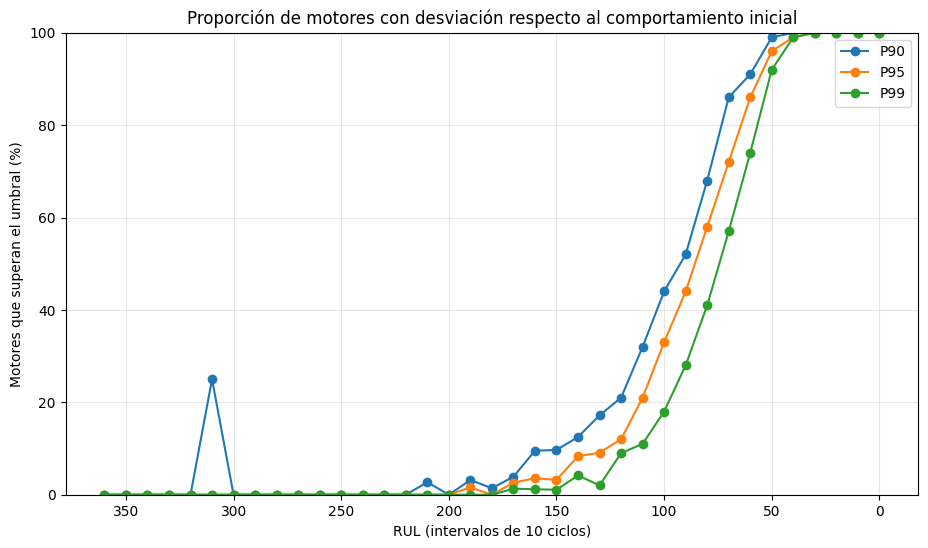

In [ ]:
plt.figure(figsize=(11, 6))

for percentile in ["P90", "P95", "P99"]:
    plt.plot(
        proportion_by_rul["RUL_bin"],
        proportion_by_rul[percentile] * 100,
        marker="o",
        label=percentile
    )

plt.xlabel("RUL (intervalos de 10 ciclos)")
plt.ylabel("Motores que superan el umbral (%)")
plt.title("Proporción de motores con desviación respecto al comportamiento inicial")

plt.gca().invert_xaxis()
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

El análisis a nivel de unidad confirma que la desviación respecto al comportamiento inicial no aparece simultáneamente en todos los motores, sino que se extiende progresivamente entre las distintas trayectorias conforme disminuye la vida útil restante.

Para los tres umbrales analizados, la proporción de motores que presenta una desviación superior a la referencia es reducida para valores elevados de RUL y aumenta de forma progresiva al aproximarse el final de vida.

Utilizando, por ejemplo, el percentil 95 como referencia, únicamente alrededor del 3 % de los motores supera el umbral en RUL = 150, mientras que esta proporción aumenta al 12 % en RUL = 120, al 33 % en RUL = 100, al 44 % en RUL = 90 y al 58 % en RUL = 80. En etapas posteriores la desviación se generaliza progresivamente, alcanzando el 86 % de los motores en RUL = 60.

Estos resultados muestran que no existe un punto único que pueda interpretarse como el inicio físico de la degradación para todos los motores. En su lugar, se observa una región de transición progresiva, coherente con la variabilidad existente entre las distintas trayectorias de FD001.

Además, los intervalos correspondientes a esta región presentan una elevada representación de motores, por lo que el patrón observado no depende únicamente de unas pocas trayectorias especialmente largas.

#### 4.5.12. Selección del valor máximo de RUL

A partir de los diferentes análisis realizados se establece finalmente un valor máximo de **120 ciclos** para la representación limitada de la RUL en FD001.

La selección no se basa en considerar este valor como el instante físico exacto de inicio de la degradación. Los resultados obtenidos muestran que la separación respecto al comportamiento inicial se produce de forma progresiva y no simultánea entre todos los motores.

El análisis basado en percentiles sitúa aproximadamente entre 80 y 100 ciclos de RUL la región en la que el índice conjunto supera de forma sostenida los niveles característicos de la referencia inicial. El análisis a nivel de motor muestra igualmente un incremento progresivo de la proporción de unidades que superan dichos umbrales conforme disminuye la RUL.

A partir de estos resultados, se adopta un valor ligeramente anterior, RUL_MAX = 120, con el objetivo de conservar dentro de la región lineal una parte previa a la transición más evidente. De esta forma, el modelo comienza a diferenciar valores de RUL antes de que la desviación conjunta se encuentre claramente establecida en una proporción elevada de motores.

Por tanto, `RUL_MAX = 120` se considera una decisión de modelado basada en el comportamiento observado en FD001, y no una estimación del instante físico exacto de inicio de la degradación. El límite permite evitar exigir al modelo una diferenciación precisa entre valores muy elevados de RUL, manteniendo al mismo tiempo información temporal en la región previa y posterior a la transición identificada.

#### 4.5.13. Construcción de la RUL limitada

Una vez establecido el límite máximo en 120 ciclos, se construye la variable objetivo `RUL_piecewise`.

Para observaciones con una RUL lineal superior a 120 ciclos se asignará un valor constante de 120. Para valores iguales o inferiores al límite se conservará la RUL lineal original.

De esta forma, la variable objetivo representa una primera región en la que no se exige diferenciar entre valores elevados de vida útil restante y una segunda región en la que la RUL disminuye linealmente hasta alcanzar 0 en el final de vida.

In [ ]:
RUL_MAX = 120

train_processed["RUL_piecewise"] = (
    train_processed["RUL"].clip(upper=RUL_MAX)
)

train_processed[
    ["unit", "cycle", "RUL", "RUL_piecewise"]
].head(10)

,unit,cycle,RUL,RUL_piecewise
0,1,1,191,120
1,1,2,190,120
2,1,3,189,120
3,1,4,188,120
4,1,5,187,120
5,1,6,186,120
6,1,7,185,120
7,1,8,184,120
8,1,9,183,120
9,1,10,182,120


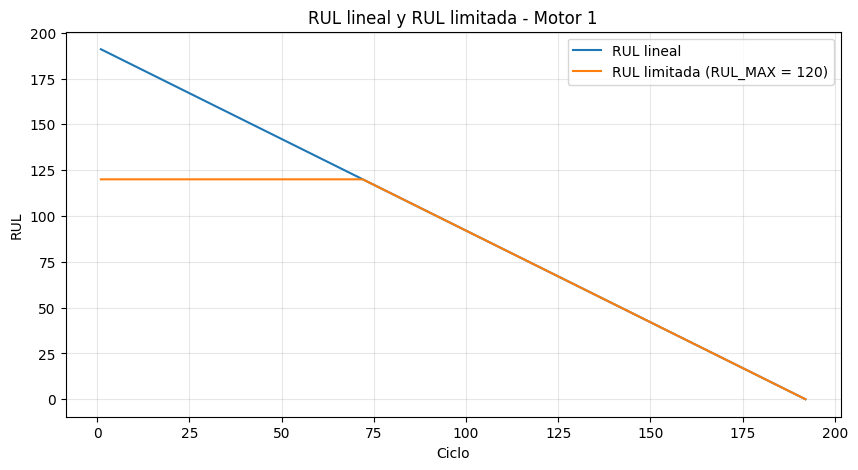

In [ ]:
engine_1_rul = train_processed[
    train_processed["unit"] == 1
]

plt.figure(figsize=(10, 5))

plt.plot(
    engine_1_rul["cycle"],
    engine_1_rul["RUL"],
    label="RUL lineal"
)

plt.plot(
    engine_1_rul["cycle"],
    engine_1_rul["RUL_piecewise"],
    label="RUL limitada (RUL_MAX = 120)"
)

plt.xlabel("Ciclo")
plt.ylabel("RUL")
plt.title("RUL lineal y RUL limitada - Motor 1")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

La comparación entre la RUL lineal y la RUL limitada para el motor 1 permite comprobar el funcionamiento de la transformación aplicada.

La RUL lineal comienza en 191 ciclos y disminuye de forma continua hasta alcanzar 0 en el último ciclo de la trayectoria. En cambio, la RUL limitada permanece constante en 120 mientras la RUL lineal es superior a dicho valor.

A partir del momento en que la RUL lineal alcanza los 120 ciclos, ambas representaciones coinciden y disminuyen conjuntamente hasta el final de vida.

Por tanto, la transformación conserva la información temporal de la RUL durante la región en la que las señales muestran una evolución progresivamente asociada a la degradación, mientras que evita establecer diferencias entre valores elevados de RUL durante las etapas iniciales.

### 4.6. Conclusiones sobre la preparación de la RUL

El análisis realizado sobre FD001 ha permitido definir dos representaciones de la vida útil restante: la RUL lineal original y una RUL limitada con un máximo de 120 ciclos.

La selección de este límite se ha realizado a partir del comportamiento observado en los propios datos. Para ello, se ha estudiado la evolución de sensores relacionados con la degradación, se ha definido una referencia inicial específica para cada motor y se ha construido un índice conjunto que cuantifica la desviación de las señales respecto a dicho comportamiento inicial.

Los resultados muestran una primera región de relativa estabilidad seguida de una desviación progresiva que se intensifica conforme disminuye la vida útil restante. El análisis basado en percentiles sitúa aproximadamente entre **80 y 100 ciclos de RUL** la región en la que la desviación conjunta supera de forma sostenida los niveles característicos de la referencia inicial. El análisis adicional a nivel de motor confirma que esta transición no se produce simultáneamente en todas las unidades, sino de forma gradual.

También se evaluó un procedimiento de regresión segmentada, cuyo mínimo error se situó alrededor de 50 ciclos de RUL. Sin embargo, este punto representa principalmente el cambio hacia una fase de crecimiento más pronunciado del índice y no necesariamente el comienzo de la desviación respecto al comportamiento inicial, por lo que no se utilizó como criterio único para definir el límite.

Considerando conjuntamente estos resultados, se estableció `RUL_MAX = 120` como decisión de modelado para FD001. Se seleccionó un valor ligeramente anterior a la región de transición más evidente con el objetivo de conservar dentro de la región lineal una parte previa a dicha transición. Este valor no representa un instante físico exacto de inicio de la degradación, sino el límite a partir del cual se utilizará una RUL decreciente para el posterior desarrollo de los modelos de prognosis.

La RUL lineal se conservará como información original y para posibles análisis comparativos, mientras que `RUL_piecewise` se utilizará inicialmente como variable objetivo principal en la tarea de estimación de vida útil restante.

## 5. Escalado de las variables predictoras

Las variables seleccionadas como predictoras presentan diferentes rangos y escalas numéricas. Estas diferencias pueden afectar especialmente a determinados algoritmos de Machine Learning y Deep Learning, por lo que resulta conveniente considerar transformaciones de escalado antes del modelado.

Cuando sea necesario, el escalado se aplicará exclusivamente sobre los sensores seleccionados como variables predictoras. Las variables `unit` y `cycle` se conservarán sin transformar debido a su función estructural, mientras que las variables objetivo `RUL` y `RUL_piecewise` tampoco se incluirán en esta transformación.

Para evitar fugas de información (*data leakage*), los parámetros necesarios para realizar el escalado se estimarán utilizando exclusivamente los datos de entrenamiento correspondientes a cada partición. Posteriormente, la misma transformación se aplicará a los datos de validación o test, sin utilizar información de estos conjuntos para calcular los parámetros.

En este notebook se conservarán los valores originales de los sensores, realizando las transformaciones de escalado posteriormente según las necesidades de cada modelo.

### 5.1. Análisis de las escalas de los sensores seleccionados

Antes de aplicar una técnica de escalado se analizarán los rangos y la dispersión de las variables predictoras seleccionadas.

El objetivo es comprobar las diferencias de magnitud existentes entre los sensores y estudiar sus características para valorar las necesidades de escalado durante el modelado posterior. Este análisis es especialmente relevante debido a que posteriormente se compararán diferentes técnicas de Machine Learning y Deep Learning, algunas de las cuales pueden ser sensibles a la escala de las variables de entrada.

In [ ]:
sensor_stats = (
    train_processed[sensor_features]
    .describe()
    .T
)

print(sensor_stats)

             count         mean        std        min        25%        50%  \
sensor_2   20631.0   642.680934   0.500053   641.2100   642.3250   642.6400   
sensor_3   20631.0  1590.523119   6.131150  1571.0400  1586.2600  1590.1000   
sensor_4   20631.0  1408.933782   9.000605  1382.2500  1402.3600  1408.0400   
sensor_7   20631.0   553.367711   0.885092   549.8500   552.8100   553.4400   
sensor_8   20631.0  2388.096652   0.070985  2387.9000  2388.0500  2388.0900   
sensor_9   20631.0  9065.242941  22.082880  9021.7300  9053.1000  9060.6600   
sensor_11  20631.0    47.541168   0.267087    46.8500    47.3500    47.5100   
sensor_12  20631.0   521.413470   0.737553   518.6900   520.9600   521.4800   
sensor_13  20631.0  2388.096152   0.071919  2387.8800  2388.0400  2388.0900   
sensor_14  20631.0  8143.752722  19.076176  8099.9400  8133.2450  8140.5400   
sensor_15  20631.0     8.442146   0.037505     8.3249     8.4149     8.4389   
sensor_17  20631.0   393.210654   1.548763   388.000

Los estadísticos descriptivos muestran diferencias importantes en la magnitud y dispersión de las variables predictoras seleccionadas.

Mientras algunos sensores presentan valores relativamente reducidos, como `sensor_15`, `sensor_20` o `sensor_21`, otros trabajan con magnitudes considerablemente superiores. Por ejemplo, `sensor_9` y `sensor_14` presentan valores medios superiores a 8.000, mientras que `sensor_3` y `sensor_4` se sitúan alrededor de 1.500 y 1.400 respectivamente.

También existen diferencias importantes en la dispersión de las variables. Las desviaciones estándar varían desde valores inferiores a 0,1 en algunos sensores hasta valores superiores a 20 en otros.

Estas diferencias confirman que las variables predictoras no se encuentran en una escala comparable. Por tanto, será necesario aplicar una transformación antes de utilizar aquellos modelos cuyo entrenamiento sea sensible a la magnitud de las variables de entrada.

No obstante, la selección del método de escalado no se realizará únicamente a partir de estos rangos, sino que se tendrá también en cuenta la forma de las distribuciones de los sensores.

### 5.2. Distribución de las variables predictoras

Además de las diferencias de escala, resulta conveniente analizar la forma de las distribuciones de las variables predictoras.

La presencia de distribuciones asimétricas, valores extremos o rangos muy diferentes puede influir en la elección del procedimiento de escalado. Para ello, se representarán mediante histogramas los 14 sensores seleccionados.

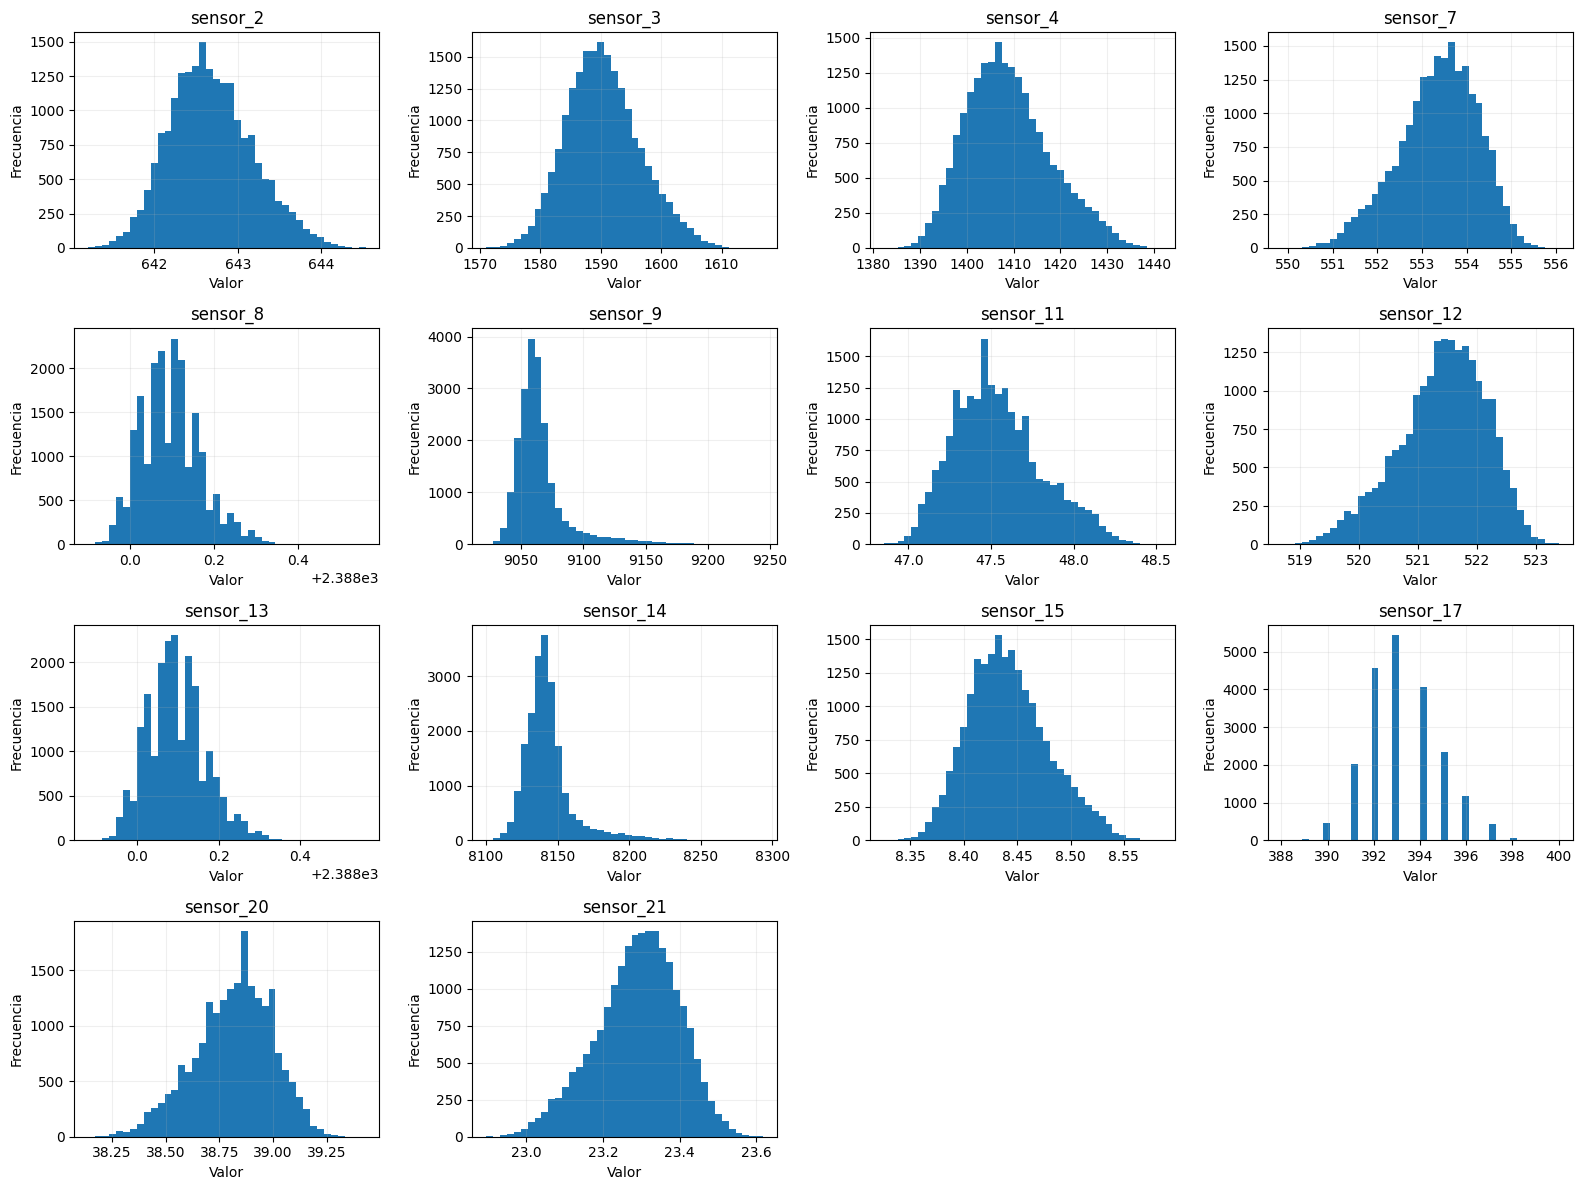

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()

for i, sensor in enumerate(sensor_features):
    axes[i].hist(
        train_processed[sensor],
        bins=40
    )

    axes[i].set_title(sensor)
    axes[i].set_xlabel("Valor")
    axes[i].set_ylabel("Frecuencia")
    axes[i].grid(alpha=0.2)

# Ocultar los ejes sobrantes
for j in range(len(sensor_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

Las distribuciones de los sensores seleccionados presentan características diferentes. Algunas variables muestran distribuciones aproximadamente unimodales y relativamente simétricas, mientras que otras presentan cierto grado de asimetría o una estructura más discreta.

En particular, sensores como `sensor_8`, `sensor_13` y `sensor_17` presentan concentraciones en determinados valores, mientras que otros, como `sensor_9` o `sensor_14`, muestran una mayor asimetría hacia valores elevados.

No obstante, no se observan valores extremos claramente aislados que justifiquen por sí mismos la aplicación de un escalado robusto. Además, las colas presentes en algunas distribuciones pueden estar relacionadas con la propia evolución de la degradación y, por tanto, no deben interpretarse automáticamente como valores anómalos que deban eliminarse.

Considerando conjuntamente estas distribuciones y las diferencias de escala identificadas anteriormente, se considera conveniente aplicar técnicas de escalado en aquellos modelos sensibles a la magnitud de las variables de entrada. No obstante, los sensores se conservarán sin transformar en este notebook, realizando el escalado posteriormente según las necesidades de cada algoritmo y del procedimiento de validación utilizado.

## 6. Preparación y almacenamiento de los datos preprocesados

Una vez realizadas las principales tareas de preprocesamiento sobre FD001, se prepararán los conjuntos de datos que servirán como punto de partida para las siguientes etapas del proyecto.

Hasta este punto se han identificado y eliminado las variables constantes y se ha excluido inicialmente `sensor_6` por su variabilidad extremadamente reducida. Además, se han definido las variables predictoras y estructurales, se ha preparado la variable objetivo para la tarea de prognosis y se han analizado las escalas de los sensores seleccionados, conservando sus valores originales.

En esta etapa final se comprobará la estructura de los conjuntos resultantes y se almacenarán los datos preprocesados. No se construirán todavía representaciones específicas para determinados modelos, como ventanas temporales, ya que estas transformaciones dependerán de las necesidades de cada tarea y se realizarán posteriormente en los notebooks correspondientes.

### 6.1. Revisión de la estructura final

Antes de almacenar los conjuntos preprocesados se revisará su estructura final para comprobar que contienen las variables necesarias para las siguientes etapas del proyecto.

Las variables `unit` y `cycle` se mantienen como información estructural. Las variables operativas conservadas permanecen disponibles para posibles análisis posteriores, aunque no forman parte de la selección inicial de predictores para FD001.

Los 14 sensores seleccionados constituyen las variables predictoras iniciales y conservan sus valores originales, sin aplicar transformaciones de escalado. En el conjunto de entrenamiento se conservan además tanto la RUL lineal como la RUL limitada.

El conjunto de test no contiene estas variables objetivo a nivel de ciclo. El archivo `RUL_FD001.txt` proporciona de forma independiente la vida útil restante correspondiente al último ciclo observado de cada motor de test.

In [ ]:
print("Columnas finales de TRAIN:")
print(train_processed.columns.tolist())

print("\nColumnas finales de TEST:")
print(test_processed.columns.tolist())

print("\nNúmero de columnas:")
print(f"Train: {train_processed.shape[1]}")
print(f"Test:  {test_processed.shape[1]}")

Columnas finales de TRAIN:
['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'RUL', 'RUL_piecewise']

Columnas finales de TEST:
['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Número de columnas:
Train: 20
Test:  18


In [ ]:
print("\nVariables predictoras seleccionadas:")
print(sensor_features)

print("\nNúmero de sensores:", len(sensor_features))

print(
    "\nTodos presentes en train:",
    all(sensor in train_processed.columns for sensor in sensor_features)
)

print(
    "Todos presentes en test:",
    all(sensor in test_processed.columns for sensor in sensor_features)
)


Variables predictoras seleccionadas:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Número de sensores: 14

Todos presentes en train: True
Todos presentes en test: True


La revisión de los conjuntos preprocesados confirma que se mantiene la estructura definida durante las etapas anteriores.

El conjunto de entrenamiento contiene 20 variables, incluyendo las variables estructurales `unit` y `cycle`, las dos variables operativas conservadas, los 14 sensores seleccionados y las variables objetivo `RUL` y `RUL_piecewise`.

El conjunto de test contiene 18 variables y mantiene la misma estructura de entrada que el conjunto de entrenamiento, pero no incluye las variables objetivo. Los 14 sensores seleccionados como predictores se encuentran correctamente disponibles en ambos conjuntos.

Por tanto, los conjuntos presentan una estructura coherente para su utilización en las siguientes etapas del proyecto.

### 6.2. Comprobación de la integridad temporal

Dado que las observaciones de C-MAPSS forman trayectorias temporales independientes para cada motor, es necesario comprobar que el preprocesamiento no ha alterado su estructura.

Se verificará que se mantienen las 100 unidades originales y que los ciclos permanecen ordenados dentro de cada trayectoria. Esta estructura será necesaria posteriormente para realizar análisis temporales y, cuando el modelo lo requiera, construir secuencias de observaciones.

In [ ]:
def check_temporal_order(df):
    return (
        df.groupby("unit")["cycle"]
        .apply(lambda x: x.is_monotonic_increasing)
        .all()
    )

print("TRAIN")
print("Número de motores:", train_processed["unit"].nunique())
print("Ciclos ordenados:", check_temporal_order(train_processed))

print("\nTEST")
print("Número de motores:", test_processed["unit"].nunique())
print("Ciclos ordenados:", check_temporal_order(test_processed))

TRAIN
Número de motores: 100
Ciclos ordenados: True

TEST
Número de motores: 100
Ciclos ordenados: True


In [ ]:
train_duplicates = train_processed.duplicated(
    subset=["unit", "cycle"]
).sum()

test_duplicates = test_processed.duplicated(
    subset=["unit", "cycle"]
).sum()

print("\nDuplicados unit-cycle en train:", train_duplicates)
print("Duplicados unit-cycle en test:", test_duplicates)

# Comprobar que no se han perdido ni alterado observaciones
train_structure_ok = train_processed[
    ["unit", "cycle"]
].equals(train[["unit", "cycle"]])

test_structure_ok = test_processed[
    ["unit", "cycle"]
].equals(test[["unit", "cycle"]])

print("\nEstructura original conservada:")
print("Train:", train_structure_ok)
print("Test:", test_structure_ok)


Duplicados unit-cycle en train: 0
Duplicados unit-cycle en test: 0

Estructura original conservada:
Train: True
Test: True


La comprobación de la estructura temporal confirma que el preprocesamiento no ha alterado las trayectorias originales de FD001.

Tanto el conjunto de entrenamiento como el conjunto de test mantienen las 100 unidades originales y los ciclos permanecen correctamente ordenados dentro de cada motor. Además, no se han identificado registros duplicados para ninguna combinación de `unit` y `cycle`.

Por tanto, los conjuntos preprocesados conservan la estructura temporal necesaria para los análisis y modelos posteriores.

### 6.3. Almacenamiento de los datos preprocesados

Una vez comprobada la estructura e integridad de los conjuntos resultantes, se almacenarán los datos preprocesados para su utilización en las siguientes etapas del proyecto.

Se guardarán de forma independiente los conjuntos de entrenamiento y test. De esta forma, los siguientes notebooks podrán partir directamente de los datos preparados sin necesidad de repetir las operaciones realizadas durante este preprocesamiento.

También se almacenará la configuración del preprocesamiento, incluyendo los sensores seleccionados, las variables excluidas y el límite utilizado para construir la RUL limitada. No se guardará ningún escalador, ya que los sensores conservarán sus valores originales y las transformaciones necesarias se ajustarán posteriormente durante el entrenamiento de cada modelo.

In [ ]:
os.makedirs(PROCESSED_DATA_PATH, exist_ok=True)

# Guardar conjuntos preprocesados sin escalar
train_processed.to_csv(
    f"{PROCESSED_DATA_PATH}/train_FD001_preprocessed.csv",
    index=False
)

test_processed.to_csv(
    f"{PROCESSED_DATA_PATH}/test_FD001_preprocessed.csv",
    index=False
)

# Guardar la configuración del preprocesamiento
preprocessing_info = {
    "sensor_features": sensor_features,
    "columns_to_drop": columns_to_drop,
    "RUL_MAX": RUL_MAX
}

joblib.dump(
    preprocessing_info,
    f"{PROCESSED_DATA_PATH}/preprocessing_FD001.pkl"
)

print("Datos preprocesados guardados correctamente.")

Datos preprocesados guardados correctamente.


### 6.4. Verificación de los archivos almacenados

Finalmente, se comprobará que los archivos generados pueden recuperarse correctamente y que mantienen las dimensiones y la información de preprocesamiento esperadas.

Esta verificación permite asegurar que los siguientes notebooks podrán utilizar directamente los resultados obtenidos en esta etapa.

In [ ]:
train_check = pd.read_csv(
    f"{PROCESSED_DATA_PATH}/train_FD001_preprocessed.csv"
)

test_check = pd.read_csv(
    f"{PROCESSED_DATA_PATH}/test_FD001_preprocessed.csv"
)

preprocessing_check = joblib.load(
    f"{PROCESSED_DATA_PATH}/preprocessing_FD001.pkl"
)

print("Train:", train_check.shape)
print("Test:", test_check.shape)

print("\nSensores guardados:")
print(preprocessing_check["sensor_features"])

print("\nVariables excluidas:")
print(preprocessing_check["columns_to_drop"])

print("\nRUL_MAX guardado:")
print(preprocessing_check["RUL_MAX"])

# Verificar que los archivos conservan la estructura esperada
assert train_check.columns.tolist() == train_processed.columns.tolist()
assert test_check.columns.tolist() == test_processed.columns.tolist()

assert train_check.shape == train_processed.shape
assert test_check.shape == test_processed.shape

# Verificar que los sensores guardados no han sido escalados
np.testing.assert_allclose(
    train_check[sensor_features].to_numpy(),
    train[sensor_features].to_numpy(),
    rtol=1e-7,
    atol=1e-8
)

np.testing.assert_allclose(
    test_check[sensor_features].to_numpy(),
    test[sensor_features].to_numpy(),
    rtol=1e-7,
    atol=1e-8
)

print("\nVerificaciones completadas correctamente.")

Train: (20631, 20)
Test: (13096, 18)

Sensores guardados:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Variables excluidas:
['op_setting_3', 'sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

RUL_MAX guardado:
120

Verificaciones completadas correctamente.


La carga de los archivos almacenados confirma que el proceso de guardado se ha realizado correctamente.

El conjunto de entrenamiento recuperado mantiene sus 20.631 observaciones y 20 variables, mientras que el conjunto de test conserva 13.096 observaciones y 18 variables. Asimismo, el archivo de configuración contiene los 14 sensores seleccionados, las variables excluidas y el valor `RUL_MAX = 120` utilizado para construir la RUL limitada.

Las comprobaciones realizadas confirman que los conjuntos almacenados mantienen las columnas y dimensiones esperadas y que los sensores conservan sus valores originales, sin transformaciones de escalado.

Por tanto, los resultados de esta etapa quedan almacenados de forma reproducible y podrán utilizarse directamente en los siguientes notebooks sin necesidad de repetir el proceso de preparación de los datos.

## 7. Conclusiones del preprocesamiento

En este notebook se ha realizado el preprocesamiento general del subconjunto FD001 con el objetivo de obtener una base de datos consistente y reproducible para las posteriores tareas de mantenimiento predictivo.

En primer lugar, se analizaron las variables disponibles y se identificaron aquellas que no aportaban variabilidad en FD001. Se eliminaron `op_setting_3`, `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18` y `sensor_19` por presentar valores constantes. Asimismo, `sensor_6` se excluyó inicialmente debido a su variabilidad extremadamente reducida y al predominio de uno de sus dos valores, como decisión inicial de simplificación de las variables predictoras.

Las variables `unit` y `cycle` se conservaron como variables estructurales para identificar los motores y mantener la organización temporal de las observaciones. Las variables operativas `op_setting_1` y `op_setting_2` también se conservaron en los conjuntos procesados, aunque no se incluyeron inicialmente entre los predictores debido a que FD001 representa una única condición operativa y sus variaciones son reducidas.

Como resultado, se seleccionaron inicialmente **14 sensores como variables predictoras**: `sensor_2`, `sensor_3`, `sensor_4`, `sensor_7`, `sensor_8`, `sensor_9`, `sensor_11`, `sensor_12`, `sensor_13`, `sensor_14`, `sensor_15`, `sensor_17`, `sensor_20` y `sensor_21`.

Para la tarea de prognosis se conservaron dos representaciones de la vida útil restante. La primera corresponde a la RUL lineal original, mientras que la segunda utiliza una RUL limitada mediante `RUL_MAX = 120`. El análisis de la evolución conjunta de varios sensores respecto a una referencia inicial definida para cada motor permitió identificar una región de transición progresiva, más evidente aproximadamente entre **80 y 100 ciclos de RUL**. A partir de estos resultados, se seleccionó `RUL_MAX = 120` como un límite ligeramente anterior a dicha región, con el objetivo de conservar dentro de la región lineal una parte previa a la transición. Por tanto, este valor debe interpretarse como una decisión de modelado y no como la identificación de un instante físico exacto de inicio de la degradación.

Posteriormente, se analizaron las escalas y distribuciones de los 14 sensores seleccionados, identificando diferencias importantes en sus magnitudes y dispersiones. Estas características justifican la necesidad de considerar procedimientos de escalado para determinados algoritmos de Machine Learning y Deep Learning. No obstante, los sensores se conservaron con sus valores originales, dejando las transformaciones de escalado para los notebooks de modelado, según las necesidades de cada algoritmo y del procedimiento de validación utilizado.

Finalmente, se comprobó que los conjuntos resultantes mantienen las 100 unidades originales, el orden temporal de los ciclos y la ausencia de duplicados para las combinaciones de motor y ciclo. Los datos preprocesados se almacenaron conservando los valores originales de los sensores seleccionados, junto con la configuración del preprocesamiento, para su utilización en las siguientes etapas del proyecto.

El preprocesamiento realizado constituye una preparación general de FD001. Las transformaciones específicas que puedan requerir determinadas tareas o modelos, como la selección de observaciones de referencia para detección de anomalías o la construcción de secuencias temporales para modelos de prognosis, se definirán posteriormente en los notebooks correspondientes.